# Solar Filament Segmentation — MAGFiLO 2026 v0.50-lite
## Kaggle inference using an existing trained checkpoint

This is the original `dl_037.ipynb` workflow adapted to use an uploaded checkpoint instead of training the model again. The architecture, solar-physics preprocessing, validation tuning, wider four-scale TTA, instance-quality filter, BatchNorm test adaptation, optional MC-Dropout blend, smoothing sweep, and submission generation are retained.

The checkpoint staging cell copies `best_ema.pt` / `best_ema_final.pt` into `/kaggle/working/best_ema.pt`, which is the path expected by the original notebook. The training cell is guarded to skip training whenever that checkpoint is present.

**Runtime note:** this still recomputes the original notebook's validation and post-training stages. It does not resume a previous Kaggle kernel's in-memory state. The four-scale TTA, validation tuning, and BN adaptation can take many hours.


In [10]:
!pip -q install segmentation-models-pytorch pycocotools scikit-image scikit-learn tqdm optuna

In [11]:
import os, gc, json, time, copy, random, glob, pickle, warnings
# Must be set BEFORE torch is imported to take effect
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.utils.checkpoint import checkpoint as grad_ckpt
from torch.optim.swa_utils import AveragedModel, SWALR, update_bn

from pycocotools import mask as coco_rle
from skimage.filters import apply_hysteresis_threshold
from skimage.morphology import skeletonize
from skimage.segmentation import watershed
from skimage.measure import label as connected_components, regionprops
from scipy import ndimage as ndi
import segmentation_models_pytorch as smp
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GroupKFold
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

warnings.filterwarnings("ignore")
cv2.setNumThreads(1)

# ---- Speed / quality preset --------------------------------------------------
# "fast"    -> fits 14-16 GiB GPU without OOM  (recommended default)
# "quality" -> use only if you have >= 24 GiB VRAM
SPEED = "quality"

_PRESETS = {
    # crop=384, batch=4 x accum=2 = effective 8, 30 epochs
    "fast":    dict(IMG_SIZE=768,  CROP=384, EPOCHS=30, SWA_EPOCHS=5,
                    STEPS=120, BATCH=4, ACCUM=2,
                    SKEL_ITERS=6,  DIST_SCALE=12.0),
    # crop=512, batch=2 x accum=4 = effective 8, 45 epochs
    "quality": dict(IMG_SIZE=1024, CROP=512, EPOCHS=45, SWA_EPOCHS=8,
                    STEPS=150, BATCH=2, ACCUM=4,
                    SKEL_ITERS=10, DIST_SCALE=16.0),
}

class Cfg:
    NATIVE        = 2048
    ENCODER       = "timm-efficientnet-b5"
    ENC_WEIGHTS   = "noisy-student"
    DECODER       = "unetplusplus"
    LR            = 2e-4
    WD            = 1e-4
    EMA_MOM       = 0.9960
    POS_BIAS      = 0.72
    VAL_RATIO     = 0.15
    W_FOCAL       = 0.6
    W_LOVASZ      = 0.4
    W_DICE        = 0.8
    W_CLDICE      = 0.5
    W_SPINE       = 0.5
    W_DIST        = 0.2
    FOCAL_ALPHA   = 0.75
    FOCAL_GAMMA   = 2.0
    LABEL_SMOOTH  = 0.04
    CROP_SCALES   = (0.75, 1.0, 1.25)
    SOFT_LABELS   = True
    USE_CLDICE    = True
    USE_SPINE     = True
    USE_SWA       = True
    # Memory knobs
    USE_GRAD_CKPT = True   # encoder activation checkpointing: ~30% VRAM, ~15% slower
    SEED          = 42
    NUM_WORKERS   = min(2, os.cpu_count() or 1)
    OUTDIR        = "/kaggle/working" if os.path.exists("/kaggle/working") else "./out"

for k, v in _PRESETS[SPEED].items():
    setattr(Cfg, k, v)

SC = Cfg.IMG_SIZE / 1024.0
os.makedirs(Cfg.OUTDIR, exist_ok=True)

def fix_seeds(s=Cfg.SEED):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    os.environ["PYTHONHASHSEED"] = str(s)

fix_seeds()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True

if DEVICE.type == "cuda":
    torch.cuda.empty_cache()
    props = torch.cuda.get_device_properties(0)
    vram  = props.total_memory / 1024**3
    print(f"GPU: {props.name}  VRAM: {vram:.1f} GiB")
    if vram < 20 and SPEED == "quality":
        print("WARNING: 'quality' preset may OOM on this GPU. Consider SPEED='fast'")

print(f"device={DEVICE}  speed={SPEED}  encoder={Cfg.ENCODER}")
print(f"crop={Cfg.CROP}  batch={Cfg.BATCH}  accum={Cfg.ACCUM}  "
      f"effective_batch={Cfg.BATCH*Cfg.ACCUM}  grad_ckpt={Cfg.USE_GRAD_CKPT}")


GPU: Tesla T4  VRAM: 14.6 GiB
device=cuda  speed=quality  encoder=timm-efficientnet-b5
crop=512  batch=2  accum=4  effective_batch=8  grad_ckpt=True


In [12]:
# ---- Locate competition data ------------------------------------------------
hits = (
    glob.glob("/kaggle/input/**/MAGFiLO_1.0_Annotations_kaggle2026_train.json", recursive=True)
  + glob.glob("/content/**/MAGFiLO_1.0_Annotations_kaggle2026_train.json",      recursive=True)
  + glob.glob("./**/MAGFiLO_1.0_Annotations_kaggle2026_train.json",             recursive=True)
)
if not hits:
    raise FileNotFoundError(
        "Can't find the annotation JSON. "
        "Add the competition dataset in the Kaggle Input panel."
    )

ANN_JSON  = hits[0]
COMP_ROOT = Path(ANN_JSON).parent.parent
IMG_TRAIN = Path(ANN_JSON).parent / "train_images"
IMG_TEST  = COMP_ROOT / "test" / "test_images"

print(f"Annotation : {ANN_JSON}")
print(f"Train imgs : {IMG_TRAIN}  ({len(list(IMG_TRAIN.glob('*')))} files)")
print(f"Test  imgs : {IMG_TEST}   ({len(list(IMG_TEST.glob('*')))} files)")


Annotation : /kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json
Train imgs : /kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/train_images  (707 files)
Test  imgs : /kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/test/test_images   (180 files)


In [13]:
# ─── Stage uploaded checkpoint (including Kaggle Model artifact folders) ───────
from pathlib import Path
import os, shutil, zipfile

INPUT_ROOT = Path("/kaggle/input")
OUT_DIR = Path(Cfg.OUTDIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)
TARGET_WEIGHTS = OUT_DIR / "best_ema.pt"

preferred_names = [
    "best_ema.pt", "best_ema_final.pt", "best_ema.pth", "best_ema_final.pth",
]
candidates = []
for name in preferred_names:
    candidates.extend(p for p in INPUT_ROOT.rglob(name) if p.is_file())

# Look for explicitly named checkpoint files before accepting other .pt files.
if not candidates:
    candidates = [
        p for p in INPUT_ROOT.rglob("*")
        if p.is_file() and p.suffix.lower() in {".pt", ".pth", ".ckpt"}
        and "resume" not in p.name.lower()
    ]

zip_candidates = [
    p for p in INPUT_ROOT.rglob("*.zip")
    if p.is_file() and any(k in p.name.lower() for k in ("best_ema", "best-model", "best_model"))
]

# Kaggle Models can expose a torch.save archive as an extracted directory:
# e.g. best_ema/{.data/, data.pkl, version, byteorder, ...}, not a .pt file.
archive_dirs = []
for pkl in INPUT_ROOT.rglob("data.pkl"):
    parent = pkl.parent
    if (parent / "version").is_file() and (parent / ".data").is_dir():
        archive_dirs.append(parent)

print("Direct checkpoint candidates:")
for p in candidates:
    print(f" - {p} ({p.stat().st_size / 1024**2:.1f} MiB)")
print("Checkpoint ZIP candidates:")
for p in zip_candidates:
    print(f" - {p} ({p.stat().st_size / 1024**2:.1f} MiB)")
print("Extracted PyTorch archive directories:")
for p in archive_dirs:
    print(f" - {p}")

if candidates:
    # Prefer the explicitly named files, then a non-resume checkpoint.
    source_weights = candidates[0]
    shutil.copy2(source_weights, TARGET_WEIGHTS)
    print(f"Copied checkpoint: {source_weights} -> {TARGET_WEIGHTS}")

elif zip_candidates:
    source_zip = zip_candidates[0]
    with zipfile.ZipFile(source_zip, "r") as zf:
        names = [n for n in zf.namelist() if not n.endswith("/")]
        inner_weights = [
            n for n in names
            if Path(n).suffix.lower() in {".pt", ".pth", ".ckpt"}
            and "resume" not in Path(n).name.lower()
        ]
        if inner_weights:
            member = sorted(inner_weights, key=lambda n: (len(n), n))[0]
            with zf.open(member) as fin, open(TARGET_WEIGHTS, "wb") as fout:
                shutil.copyfileobj(fin, fout)
            print(f"Extracted {member} from {source_zip} -> {TARGET_WEIGHTS}")
        elif any(n.endswith("/data.pkl") or n == "data.pkl" for n in names) and any(
            n.endswith("/version") or n == "version" for n in names
        ):
            shutil.copy2(source_zip, TARGET_WEIGHTS)
            print(f"Copied PyTorch serialization ZIP directly: {source_zip}")
        else:
            raise RuntimeError(
                f"{source_zip} is not a recognized checkpoint ZIP. "
                "Inspect its contents or attach the model artifact folder."
            )

elif archive_dirs:
    # Re-pack the extracted torch.save archive into a ZIP that torch.load can read.
    # PyTorch's ZIP reader requires every member to live under one common root
    # directory (e.g. best_ema/data.pkl), not at the ZIP root. The previous version
    # wrote .format_version at the root, which triggers:
    # "file in archive is not in a subdirectory: .format_version".
    source_dir = archive_dirs[0]
    archive_prefix = source_dir.name or "checkpoint"
    with zipfile.ZipFile(TARGET_WEIGHTS, "w", compression=zipfile.ZIP_STORED) as zf:
        for f in source_dir.rglob("*"):
            if f.is_file():
                relative = f.relative_to(source_dir).as_posix()
                zf.write(f, arcname=f"{archive_prefix}/{relative}")
    print(f"Repacked extracted PyTorch archive directory: {source_dir} -> {TARGET_WEIGHTS}")

else:
    # Helpful diagnostic: show a short sample of available files.
    sample = [str(p) for p in INPUT_ROOT.rglob("*") if p.is_file()][:60]
    print("Sample files under /kaggle/input:")
    for p in sample:
        print(" -", p)
    raise FileNotFoundError(
        "No usable checkpoint found. The model artifact may be attached as an extracted "
        "Kaggle Model folder; expected best_ema*.pt, a checkpoint ZIP, or a folder "
        "containing data.pkl, version, and .data/."
    )

# Validate deserialization before running expensive preprocessing/tuning.
import torch
try:
    ckpt_obj = torch.load(TARGET_WEIGHTS, map_location="cpu", weights_only=False)
except TypeError:
    ckpt_obj = torch.load(TARGET_WEIGHTS, map_location="cpu")

if not isinstance(ckpt_obj, dict):
    raise TypeError(f"Unexpected checkpoint object type: {type(ckpt_obj)}")

print("Checkpoint loaded for validation.")
print("Top-level keys (first 12):", list(ckpt_obj.keys())[:12])
if "state_dict" in ckpt_obj and isinstance(ckpt_obj["state_dict"], dict):
    print("Note: checkpoint wraps a state_dict under 'state_dict'; the downstream loader "
          "expects a raw state_dict, so check the checkpoint format before continuing.")

del ckpt_obj
print("Target checkpoint:", TARGET_WEIGHTS)


Direct checkpoint candidates:
Checkpoint ZIP candidates:
Extracted PyTorch archive directories:
 - /kaggle/input/models/samrithashree/best-model/pytorch/default/1/best_ema
Repacked extracted PyTorch archive directory: /kaggle/input/models/samrithashree/best-model/pytorch/default/1/best_ema -> /kaggle/working/best_ema.pt
Checkpoint loaded for validation.
Top-level keys (first 12): ['encoder.conv_stem.weight', 'encoder.bn1.weight', 'encoder.bn1.bias', 'encoder.bn1.running_mean', 'encoder.bn1.running_var', 'encoder.bn1.num_batches_tracked', 'encoder.blocks.0.0.conv_dw.weight', 'encoder.blocks.0.0.bn1.weight', 'encoder.blocks.0.0.bn1.bias', 'encoder.blocks.0.0.bn1.running_mean', 'encoder.blocks.0.0.bn1.running_var', 'encoder.blocks.0.0.bn1.num_batches_tracked']
Target checkpoint: /kaggle/working/best_ema.pt


In [14]:
# ─── Solar-physics 3-channel preprocessing ────────────────────────────────────
# Identical to v0.35 — the disk-detection separation and channel construction
# remain the structural differentiator vs the baseline approach.

def _kern_ellipse(k):
    k = max(3, int(round(k)))
    if k % 2 == 0: k += 1
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))


def _solar_disk_params(gray):
    """Fit a circle to the solar disk. Returns (cx, cy, r)."""
    H  = gray.shape[0]
    sc = H / 2048.0
    bl = cv2.GaussianBlur(gray, (0, 0), 4.0 * sc)
    _, th = cv2.threshold(bl, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    bw = (bl > 0.6 * th).astype(np.uint8)
    bw = cv2.morphologyEx(bw, cv2.MORPH_CLOSE, _kern_ellipse(25 * sc))
    cnts, _ = cv2.findContours(bw, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    fallback = (H * 0.5, H * 0.5, H * 0.46)
    if not cnts:
        return fallback
    (cx, cy), r = cv2.minEnclosingCircle(max(cnts, key=cv2.contourArea))
    return fallback if r < 0.29 * H or r > 0.54 * H else (float(cx), float(cy), float(r))


def solar_preprocess(gray_uint8):
    H  = gray_uint8.shape[0]
    sc = H / 2048.0
    cx, cy, r = _solar_disk_params(gray_uint8)

    yg, xg  = np.mgrid[0:H, 0:H].astype(np.float32)
    rho     = np.sqrt((xg - cx) ** 2 + (yg - cy) ** 2) / r
    disk_bw = (rho < 0.985).astype(np.uint8)

    flt = gray_uint8.astype(np.float32)
    N   = 100
    b   = np.clip((rho * N).astype(np.int32), 0, N - 1)
    bs, fs, ds = b[::2, ::2].ravel(), flt[::2, ::2].ravel(), disk_bw[::2, ::2].ravel() > 0
    order  = np.argsort(bs[ds])
    bsv, fsv = bs[ds][order], fs[ds][order]
    edges  = np.searchsorted(bsv, np.arange(N + 1))
    med_prof = np.array([
        np.median(fsv[edges[i]:edges[i+1]]) if edges[i+1] - edges[i] > 20 else np.nan
        for i in range(N)
    ], np.float32)
    idx = np.arange(N)
    ok  = ~np.isnan(med_prof)
    med_prof = np.interp(idx, idx[ok], med_prof[ok]) if ok.any() else np.full(N, 128.0, np.float32)
    med_prof = cv2.GaussianBlur(med_prof[None], (0, 0), 2.0)[0]
    bg   = np.interp(rho * N, idx + 0.5, med_prof).astype(np.float32)
    flat = flt / np.maximum(bg, 5.0)
    vals = flat[disk_bw > 0]
    med  = np.median(vals)
    mad  = np.median(np.abs(vals - med)) * 1.4826 + 1e-6
    ch0  = (np.clip((flat - med) / mad, -6, 4) + 6) / 10.0 * 255.0

    ch1 = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(16, 16)).apply(gray_uint8).astype(np.float32)

    ch0_u8 = ch0.astype(np.uint8)
    bh = cv2.morphologyEx(
        cv2.GaussianBlur(ch0_u8, (0, 0), 1.0),
        cv2.MORPH_BLACKHAT, _kern_ellipse(max(21 * sc, 7))
    ).astype(np.float32)

    x  = np.stack([ch0, ch1, np.clip(bh * 4.0, 0, 255)], axis=0)
    x[:, disk_bw == 0] = 0
    return np.clip(x, 0, 255).astype(np.uint8), disk_bw


def imread_resized(path, target):
    flags = cv2.IMREAD_REDUCED_GRAYSCALE_2 if target * 2 == Cfg.NATIVE else cv2.IMREAD_GRAYSCALE
    im = cv2.imread(str(path), flags)
    if im is None:
        raise IOError(f"Cannot read {path}")
    if im.shape[0] != target:
        im = cv2.resize(im, (target, target), interpolation=cv2.INTER_AREA)
    return im

print("Solar preprocessing ready ✓")

Solar preprocessing ready ✓


In [15]:
# ─── Parse COCO annotations ───────────────────────────────────────────────────
annot   = json.load(open(ANN_JSON))
id2meta = {im["id"]: im for im in annot["images"]}

by_stem  = defaultdict(list)
for iid, meta in id2meta.items():
    by_stem[Path(meta["file_name"]).stem].append(iid)

anns_for  = defaultdict(list)
for a in annot["annotations"]:
    anns_for[a["image_id"]].append(a)

disk2path = {p.stem: p for p in IMG_TRAIN.glob("*")
             if p.suffix.lower() in (".jpg", ".jpeg", ".png")}

print(f"Unique observations : {len(by_stem)}")
print(f"Total annotations   : {len(annot['annotations'])}")
print(f"Train images on disk: {len(disk2path)}")


def _poly_or_rle_to_mask(seg, size):
    s = size / Cfg.NATIVE
    if isinstance(seg, dict):
        rle = seg if isinstance(seg.get("counts"), (str, bytes))               else coco_rle.frPyObjects(seg, *seg["size"])
        m = coco_rle.decode(rle).astype(np.uint8)
        return cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)
    scaled = [(np.asarray(p, np.float64) * s).tolist() for p in seg if len(p) >= 6]
    if not scaled:
        return np.zeros((size, size), np.uint8)
    return coco_rle.decode(
        coco_rle.merge(coco_rle.frPyObjects(scaled, size, size))
    ).astype(np.uint8)


def _spine_to_mask(ann, size, canvas):
    pts_raw = ann.get("spine") or []
    if len(pts_raw) >= 4:
        pts = (np.array(pts_raw, np.float32).reshape(-1, 2)
               * (size / Cfg.NATIVE)).round().astype(np.int32)
        cv2.polylines(canvas, [pts.reshape(-1, 1, 2)], False, 1.0,
                      thickness=max(2, round(3 * SC)))


def build_observation(stem):
    sz = Cfg.IMG_SIZE
    x, disk = solar_preprocess(imread_resized(disk2path[stem], sz))

    soft_mask  = np.zeros((sz, sz), np.float32)
    soft_spine = np.zeros((sz, sz), np.float32)
    per_ann_instances = []

    for iid in by_stem[stem]:
        union_this = np.zeros((sz, sz), np.uint8)
        inst_this  = np.zeros((sz, sz), np.uint16)
        sp_canvas  = np.zeros((sz, sz), np.float32)
        ann_list   = sorted(anns_for[iid], key=lambda a: -int(_poly_or_rle_to_mask(a["segmentation"], sz).sum()))
        for k, a in enumerate(ann_list, start=1):
            m = _poly_or_rle_to_mask(a["segmentation"], sz)
            union_this |= m
            inst_this[m > 0] = k
            _spine_to_mask(a, sz, sp_canvas)
        soft_mask  += union_this
        soft_spine += sp_canvas
        per_ann_instances.append(inst_this)

    n = max(len(by_stem[stem]), 1)
    soft_mask  /= n
    soft_spine /= n

    if not Cfg.SOFT_LABELS:
        soft_mask = (soft_mask > 0).astype(np.float32)

    # Asymmetric label smoothing: pulls extremes slightly toward 0.5
    # to prevent the model from becoming pathologically overconfident
    eps = Cfg.LABEL_SMOOTH
    soft_mask = np.clip(soft_mask * (1 - 2 * eps) + eps, 0, 1)

    soft_spine = cv2.GaussianBlur(np.clip(soft_spine, 0, 1), (0, 0), 1.5)
    if soft_spine.max() > 0:
        soft_spine = soft_spine / soft_spine.max()

    bin_mask = (soft_mask > 0.5).astype(np.uint8)
    dist_map = np.clip(
        cv2.distanceTransform(bin_mask, cv2.DIST_L2, 3) / Cfg.DIST_SCALE, 0, 1
    )

    target = (np.stack([soft_mask, soft_spine, dist_map], axis=0) * 255).round().astype(np.uint8)

    fil_px = np.argwhere(soft_mask > 0.5)
    if len(fil_px) > 3000:
        fil_px = fil_px[np.random.RandomState(0).choice(len(fil_px), 3000, replace=False)]

    return dict(stem=stem, x=x, target=target, disk=disk,
                fil_px=fil_px, gt_instances=per_ann_instances)


CACHE = f"{Cfg.OUTDIR}/obs_cache_r{Cfg.IMG_SIZE}_soft{int(Cfg.SOFT_LABELS)}_ls{Cfg.LABEL_SMOOTH}.pkl"
if os.path.exists(CACHE):
    obs = pickle.load(open(CACHE, "rb"))
    print(f"Loaded cache: {len(obs)} observations")
else:
    valid_stems = [s for s in by_stem if s in disk2path]
    print(f"Building {len(valid_stems)} observations…")
    t0  = time.time()
    obs = {}
    for stem in tqdm(valid_stems):
        try:
            obs[stem] = build_observation(stem)
        except Exception as e:
            print(f"  skip {stem}: {e}")
    pickle.dump(obs, open(CACHE, "wb"), protocol=4)
    print(f"Done in {time.time()-t0:.0f}s")

ALL_STEMS = sorted(obs)
print(f"Total usable observations: {len(ALL_STEMS)}")

Unique observations : 707
Total annotations   : 8199
Train images on disk: 707
Building 707 observations…


  0%|          | 0/707 [00:00<?, ?it/s]

Done in 174s
Total usable observations: 707


In [16]:
# ─── Temporal train/val split (no day-level leakage) ──────────────────────────
unique_days = sorted({s[:8] for s in ALL_STEMS})
rng_split   = np.random.RandomState(Cfg.SEED + 1)
n_val       = max(1, int(len(unique_days) * Cfg.VAL_RATIO))
val_day_set = set(rng_split.choice(unique_days, n_val, replace=False))

TR_STEMS  = [s for s in ALL_STEMS if s[:8] not in val_day_set]
VAL_STEMS = [s for s in ALL_STEMS if s[:8] in val_day_set]

print(f"Days: {len(unique_days)} total  |  {n_val} held out for val")
print(f"Train: {len(TR_STEMS)} obs  |  Val: {len(VAL_STEMS)} obs")

Days: 656 total  |  98 held out for val
Train: 603 obs  |  Val: 104 obs


EDA stats:   0%|          | 0/707 [00:00<?, ?it/s]

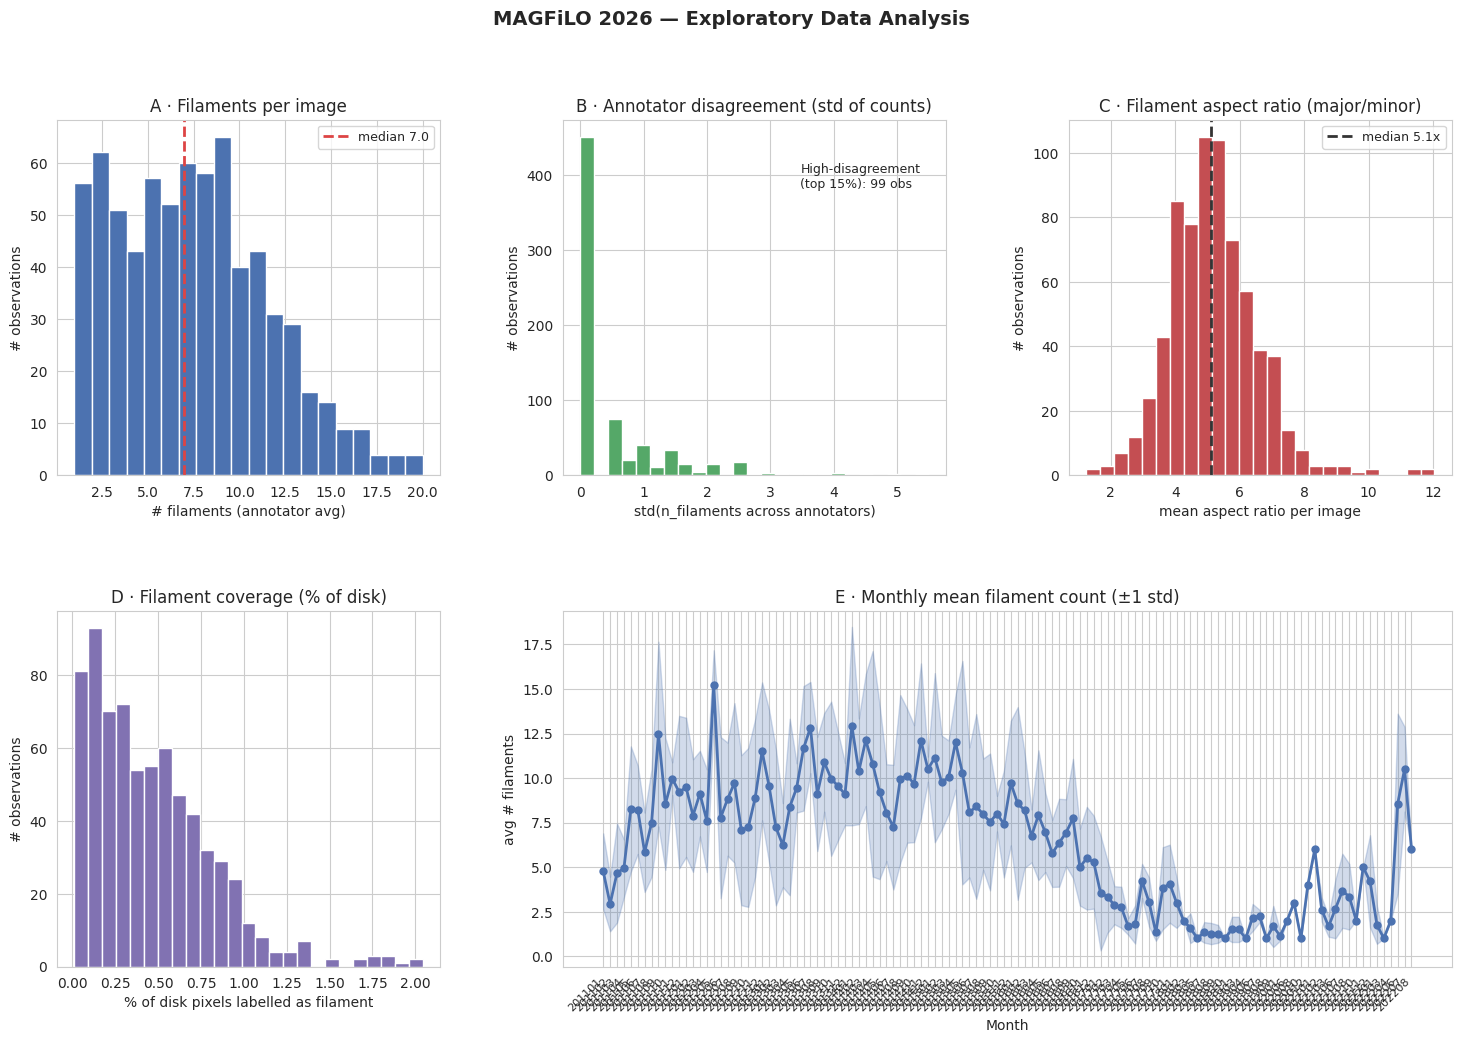


Dataset summary:
       mean_n_filaments  disagreement  coverage_pct  mean_aspect_ratio
count            707.00        707.00        707.00             707.00
mean               7.36          0.50          0.46               5.19
std                4.29          0.89          0.35               1.37
min                1.00          0.00          0.01               1.23
25%                4.00          0.00          0.18               4.27
50%                7.00          0.00          0.39               5.10
75%               10.00          0.82          0.65               5.95
max               26.00          5.50          2.04              12.04

→ High-disagreement observations (std > 1.5): 75
→ Multi-scale training motivated by aspect-ratio range: 3.7x – 6.9x


In [17]:
# ─── EDA: Dataset Characterisation ──────────────────────────────────────────
# Key questions:
#  1. How many filaments per image (and how much do annotators disagree)?
#  2. What is the size/aspect-ratio distribution of filaments?
#  3. Is solar activity correlated with filament count (temporal trend)?
#  4. How much of the solar disk do filaments occupy?
# This analysis guides architecture choices (e.g. multi-scale training is
# motivated by the wide aspect-ratio spread shown in panel C).

def _eda_stats(stem_list):
    rows = []
    for stem in tqdm(stem_list, desc="EDA stats", leave=False):
        rec = obs[stem]
        n_ann = len(rec["gt_instances"])
        inst_counts = [len(np.unique(g[g > 0])) for g in rec["gt_instances"]]
        soft = rec["target"][0].astype(np.float32) / 255.0
        disk_px = float(rec["disk"].sum())
        coverage = float((soft > 0.5).sum()) / max(disk_px, 1) * 100.0
        disagreement = float(np.std(inst_counts)) if len(inst_counts) > 1 else 0.0
        # Morphology from first annotator
        gt0 = rec["gt_instances"][0] if rec["gt_instances"] else np.zeros(soft.shape, np.uint16)
        aspect_ratios, areas = [], []
        for rp in regionprops(gt0.astype(np.int32)):
            if rp.area < 30: continue
            ar = rp.axis_major_length / max(rp.axis_minor_length, 1.0)
            aspect_ratios.append(ar)
            areas.append(rp.area)
        rows.append(dict(
            stem=stem,
            date=stem[:8],
            n_annotators=n_ann,
            mean_n_filaments=float(np.mean(inst_counts)) if inst_counts else 0,
            disagreement=disagreement,
            coverage_pct=coverage,
            mean_aspect_ratio=float(np.mean(aspect_ratios)) if aspect_ratios else 1.0,
            mean_area_px=float(np.mean(areas)) if areas else 0.0,
            n_filaments_gt0=len(aspect_ratios),
        ))
    return pd.DataFrame(rows)

eda_df = _eda_stats(ALL_STEMS)

# ── Plot ──────────────────────────────────────────────────────────────────────
sns.set_style("whitegrid")
fig = plt.figure(figsize=(18, 11))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.38, wspace=0.32)

# A: Filament count distribution
ax_a = fig.add_subplot(gs[0, 0])
eda_df["mean_n_filaments"].clip(0, 20).hist(bins=20, ax=ax_a, color="#4C72B0", edgecolor="white")
ax_a.set(title="A · Filaments per image", xlabel="# filaments (annotator avg)", ylabel="# observations")
ax_a.axvline(eda_df["mean_n_filaments"].median(), color="#DD4444", lw=2, ls="--", label=f"median {eda_df['mean_n_filaments'].median():.1f}")
ax_a.legend(fontsize=9)

# B: Annotator disagreement
ax_b = fig.add_subplot(gs[0, 1])
eda_df["disagreement"].hist(bins=25, ax=ax_b, color="#55A868", edgecolor="white")
ax_b.set(title="B · Annotator disagreement (std of counts)", xlabel="std(n_filaments across annotators)", ylabel="# observations")
high_dis = (eda_df["disagreement"] > eda_df["disagreement"].quantile(0.85)).sum()
ax_b.text(0.62, 0.88, f"High-disagreement\n(top 15%): {high_dis} obs", transform=ax_b.transAxes, fontsize=9, va="top")

# C: Aspect ratio distribution — justifies multi-scale training
ax_c = fig.add_subplot(gs[0, 2])
eda_df["mean_aspect_ratio"].clip(1, 30).hist(bins=25, ax=ax_c, color="#C44E52", edgecolor="white")
ax_c.set(title="C · Filament aspect ratio (major/minor)", xlabel="mean aspect ratio per image", ylabel="# observations")
ax_c.axvline(eda_df["mean_aspect_ratio"].median(), color="#333", lw=2, ls="--",
             label=f"median {eda_df['mean_aspect_ratio'].median():.1f}x")
ax_c.legend(fontsize=9)

# D: Solar coverage distribution
ax_d = fig.add_subplot(gs[1, 0])
eda_df["coverage_pct"].hist(bins=25, ax=ax_d, color="#8172B2", edgecolor="white")
ax_d.set(title="D · Filament coverage (% of disk)", xlabel="% of disk pixels labelled as filament", ylabel="# observations")

# E: Temporal activity — monthly average filament count
ax_e = fig.add_subplot(gs[1, 1:])
eda_df["month"] = eda_df["date"].str[:6]
monthly = eda_df.groupby("month")["mean_n_filaments"].agg(["mean", "std"]).reset_index()
ax_e.fill_between(range(len(monthly)),
                   monthly["mean"] - monthly["std"].fillna(0),
                   monthly["mean"] + monthly["std"].fillna(0),
                   alpha=0.25, color="#4C72B0")
ax_e.plot(range(len(monthly)), monthly["mean"], "o-", color="#4C72B0", lw=2, ms=5)
ax_e.set_xticks(range(len(monthly)))
ax_e.set_xticklabels(monthly["month"].tolist(), rotation=45, ha="right", fontsize=8)
ax_e.set(title="E · Monthly mean filament count (±1 std)", xlabel="Month", ylabel="avg # filaments")

fig.suptitle("MAGFiLO 2026 — Exploratory Data Analysis", fontsize=14, fontweight="bold")
plt.savefig(f"{Cfg.OUTDIR}/eda_overview.png", dpi=120, bbox_inches="tight")
plt.show()

print(f"\nDataset summary:")
print(eda_df[["mean_n_filaments","disagreement","coverage_pct","mean_aspect_ratio"]].describe().round(2))
print(f"\n→ High-disagreement observations (std > 1.5): {(eda_df['disagreement'] > 1.5).sum()}")
print(f"→ Multi-scale training motivated by aspect-ratio range: "
      f"{eda_df['mean_aspect_ratio'].quantile(0.1):.1f}x – {eda_df['mean_aspect_ratio'].quantile(0.9):.1f}x")

In [18]:
# ─── Training dataset with multi-scale filament-biased random-affine crops ──────
#
# Upgrade over v0.35: crop size is sampled from CROP_SCALES each call.
# The final patch is always resampled to Cfg.CROP so batch dimensions match.
# This forces the encoder to learn scale-invariant features, which directly
# benefits detection of both long channel-spanning filaments AND short barb fragments.

_CROP_SIZES = [int(Cfg.CROP * s) for s in Cfg.CROP_SCALES]

class SolarCropDataset(Dataset):
    def __init__(self, stem_list, total_len):
        self.records   = [obs[s] for s in stem_list]
        self.total_len = total_len

    def __len__(self):
        return self.total_len

    def __getitem__(self, _):
        rng  = np.random
        rec  = self.records[rng.randint(len(self.records))]
        H    = Cfg.IMG_SIZE
        # Multi-scale: pick a crop window size, warp it, resize to Cfg.CROP
        C_raw = int(rng.choice(_CROP_SIZES))
        C_out = Cfg.CROP

        if len(rec["fil_px"]) and rng.rand() < Cfg.POS_BIAS:
            cy, cx = rec["fil_px"][rng.randint(len(rec["fil_px"]))]
            cx += rng.randint(-C_raw // 4, C_raw // 4 + 1)
            cy += rng.randint(-C_raw // 4, C_raw // 4 + 1)
        else:
            cy, cx = rng.randint(H // 6, H - H // 6, 2)

        angle = rng.uniform(0, 360)
        scale = float(np.exp(rng.uniform(np.log(0.75), np.log(1.30))))
        M     = cv2.getRotationMatrix2D((float(cx), float(cy)), angle, scale)
        M[0, 2] += C_raw / 2 - cx
        M[1, 2] += C_raw / 2 - cy

        all_ch = np.concatenate([rec["x"], rec["target"],
                                  rec["disk"][None].astype(np.uint8) * 255], axis=0)
        warped = np.stack([
            cv2.warpAffine(ch, M, (C_raw, C_raw),
                           flags=cv2.INTER_LINEAR,
                           borderMode=cv2.BORDER_CONSTANT, borderValue=0)
            for ch in all_ch
        ], axis=0).astype(np.float32)

        # Resize all channels uniformly to the fixed output crop size
        if C_raw != C_out:
            warped = np.stack([
                cv2.resize(ch, (C_out, C_out), interpolation=cv2.INTER_LINEAR)
                for ch in warped
            ])

        x_crop = warped[:3]
        t_crop = warped[3:6] / 255.0
        v_crop = (warped[6] > 127).astype(np.float32)

        # ── Photometric augmentation ──────────────────────────────────────
        x_crop = x_crop * rng.uniform(0.85, 1.15) + rng.uniform(-15, 15)
        if rng.rand() < 0.3:
            gamma  = rng.uniform(0.75, 1.35)
            x_crop = 255.0 * np.clip(x_crop / 255.0, 0, 1) ** gamma
        if rng.rand() < 0.3:
            x_crop += rng.randn(*x_crop.shape) * rng.uniform(1, 8)
        if rng.rand() < 0.2:
            x_crop = np.stack([
                cv2.GaussianBlur(c, (0, 0), rng.uniform(0.4, 1.4)) for c in x_crop
            ])
        # Elastic deformation — mimics solar limb curvature distortion
        if rng.rand() < 0.25:
            alpha_el = rng.uniform(30, 80)
            sigma_el = rng.uniform(6, 10)
            dx = cv2.GaussianBlur((rng.rand(C_out, C_out) * 2 - 1) * alpha_el, (0, 0), sigma_el)
            dy = cv2.GaussianBlur((rng.rand(C_out, C_out) * 2 - 1) * alpha_el, (0, 0), sigma_el)
            gx, gy = np.meshgrid(np.arange(C_out), np.arange(C_out))
            map_x  = np.clip(gx + dx, 0, C_out - 1).astype(np.float32)
            map_y  = np.clip(gy + dy, 0, C_out - 1).astype(np.float32)
            x_crop = np.stack([cv2.remap(c, map_x, map_y, cv2.INTER_LINEAR) for c in x_crop])
            t_crop = np.stack([cv2.remap(c, map_x, map_y, cv2.INTER_LINEAR) for c in t_crop])
            v_crop = cv2.remap(v_crop, map_x, map_y, cv2.INTER_NEAREST)
        # Random horizontal flip
        if rng.rand() < 0.5:
            x_crop = x_crop[:, :, ::-1]
            t_crop = t_crop[:, :, ::-1]
            v_crop = v_crop[:, ::-1]

        x_crop = np.clip(x_crop, 0, 255) / 255.0
        x_crop = (x_crop - 0.5) / 0.25

        return (torch.from_numpy(np.ascontiguousarray(x_crop)).float(),
                torch.from_numpy(np.ascontiguousarray(t_crop)).float(),
                torch.from_numpy(np.ascontiguousarray(v_crop)).float())


def _worker_seed(wid):
    np.random.seed((torch.initial_seed() + wid) % 2 ** 32)

tr_dataset = SolarCropDataset(TR_STEMS, Cfg.EPOCHS * Cfg.STEPS * Cfg.BATCH * Cfg.ACCUM)
tr_loader  = DataLoader(tr_dataset, batch_size=Cfg.BATCH,
                        num_workers=Cfg.NUM_WORKERS,
                        worker_init_fn=_worker_seed,
                        drop_last=True, pin_memory=True,
                        persistent_workers=(Cfg.NUM_WORKERS > 0),
                        prefetch_factor=2 if Cfg.NUM_WORKERS > 0 else None)

print(f"Train loader: {len(tr_dataset)} crops/epoch  batch={Cfg.BATCH}")
print(f"Multi-scale crop sizes: {_CROP_SIZES} → all resized to {Cfg.CROP}")

Train loader: 54000 crops/epoch  batch=2
Multi-scale crop sizes: [384, 512, 640] → all resized to 512


In [19]:
# ─── 3-head UNet++ (mask | spine | inner-distance) ──────────────────────────────
# Upgrade: UNet++ has dense nested skip pathways that aggregate features at
# multiple scales before passing to the next decoder level.  For thin-filament
# segmentation this is more effective than plain UNet skip connections because
# filaments appear at every scale simultaneously.
# Encoder: EfficientNet-B5 (noisy-student) preferred; graceful fallbacks.

_ENCODER_FALLBACK_CHAIN = [
    ("timm-efficientnet-b5",  "noisy-student"),
    ("timm-efficientnet-b3",  "noisy-student"),
    ("efficientnet-b3",       "imagenet"),
    ("resnet50",              "imagenet"),
    ("resnet34",              "imagenet"),
]

def build_model():
    for enc, weights in _ENCODER_FALLBACK_CHAIN:
        try:
            net = smp.UnetPlusPlus(
                enc,
                encoder_weights=weights,
                in_channels=3,
                classes=3,
                decoder_attention_type="scse",
            )
            print(f"Built UNet++ · encoder={enc} · weights={weights}")
            return net
        except Exception as exc:
            print(f"  {enc}/{weights} unavailable: {exc}")
    raise RuntimeError("All encoders failed — check smp installation.")


class RunningEMA:
    """
    Exponential moving average of model weights for stable inference.
    Uses torch._foreach_lerp_ for a single fused kernel call — avoids the
    two-step mul+add pattern and is measurably faster at large parameter counts.
    """
    def __init__(self, net, momentum=Cfg.EMA_MOM):
        self.shadow = copy.deepcopy(net).eval()
        self.mom    = momentum
        for p in self.shadow.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def step(self, net):
        shadow_fp = [v for v in self.shadow.state_dict().values() if v.is_floating_point()]
        live_fp   = [v.detach() for v in net.state_dict().values() if v.is_floating_point()]
        torch._foreach_lerp_(shadow_fp, live_fp, 1.0 - self.mom)



def apply_encoder_checkpointing(net):
    # Patch individual blocks inside the smp encoder so their forward pass
    # is wrapped with torch.utils.checkpoint.  This trades ~15% compute for
    # ~30% VRAM because intermediate activations are recomputed on backward.
    if not Cfg.USE_GRAD_CKPT:
        return net
    enc = net.encoder
    for name, module in enc.named_children():
        if isinstance(module, (nn.Sequential, nn.ModuleList)):
            for i, block in enumerate(module):
                if isinstance(block, nn.Module) and len(list(block.parameters())) > 0:
                    orig_fwd = block.forward
                    def make_ckpt(f):
                        def ckpt_fwd(*args, **kwargs):
                            tensors = [a for a in args if isinstance(a, torch.Tensor)]
                            if tensors:
                                return grad_ckpt(f, *args, use_reentrant=False, **kwargs)
                            return f(*args, **kwargs)
                        return ckpt_fwd
                    block.forward = make_ckpt(orig_fwd)
    return net

print("Model architecture ready ✓")

Model architecture ready ✓


In [20]:
# ─── Losses: Focal BCE + Lovász-Hinge + soft Dice + clDice + spine + dist ─────
#
# Key upgrades over v0.35:
#   • Focal loss replaces plain BCE — down-weights the easy background pixels
#     (which dominate in solar images) and focuses gradient on hard positives.
#   • Lovász-Hinge loss replaces/augments soft Dice for the mask head.
#     Lovász directly optimises the IoU surrogate — this matches SQ in PQ.
#   Both are inline implementations with no extra pip dependency.

# ── clDice (topology-aware loss) ─────────────────────────────────────────────
def _morf_erode(t):
    return torch.min(
        -F.max_pool2d(-t, (3, 1), 1, (1, 0)),
        -F.max_pool2d(-t, (1, 3), 1, (0, 1)),
    )

def _morf_dilate(t):
    return F.max_pool2d(t, 3, 1, 1)

def _soft_skeleton(t, n_iters):
    skel = F.relu(t - _morf_dilate(_morf_erode(t)))
    for _ in range(n_iters):
        t    = _morf_erode(t)
        skel = skel + F.relu(F.relu(t - _morf_dilate(_morf_erode(t))) - skel)
    return skel

def cldice_loss(prob, target, n_iters, eps=1e-6):
    p2 = F.avg_pool2d(prob,   2)
    t2 = F.avg_pool2d(target, 2)
    sp = _soft_skeleton(p2, n_iters)
    st = _soft_skeleton(t2, n_iters)
    prec = ((sp * t2).sum() + eps) / (sp.sum() + eps)
    sens = ((st * p2).sum() + eps) / (st.sum() + eps)
    return 1.0 - 2.0 * prec * sens / (prec + sens)

# ── Soft Dice ─────────────────────────────────────────────────────────────────
def dice_loss(prob, target, valid, eps=1.0):
    p = prob * valid; t = target * valid
    num = (p * t).sum((1, 2, 3))
    den = p.sum((1, 2, 3)) + t.sum((1, 2, 3))
    return (1.0 - (2.0 * num + eps) / (den + eps)).mean()

# ── Focal BCE — replaces plain BCE for the mask head ─────────────────────────
def focal_bce(logit, target, valid, alpha=Cfg.FOCAL_ALPHA, gamma=Cfg.FOCAL_GAMMA):
    """
    alpha: balances pos/neg — set > 0.5 to give more weight to thin filament pixels.
    gamma: focusing exponent — higher = more focus on hard/misclassified pixels.
    """
    p   = torch.sigmoid(logit.float())
    ce  = F.binary_cross_entropy_with_logits(logit.float(), target, reduction="none")
    p_t = p * target + (1.0 - p) * (1.0 - target)
    alpha_t = alpha * target + (1.0 - alpha) * (1.0 - target)
    focal_w = alpha_t * (1.0 - p_t) ** gamma
    v = valid[:, None] if valid.dim() == 3 else valid
    return (focal_w * ce * v).sum() / v.sum().clamp(min=1)

# ── Lovász-Hinge — directly optimises per-pixel IoU ──────────────────────────
def _lovasz_grad(gt_sorted):
    """Lovász extension of the IoU loss (binary, sorted label helper)."""
    n  = len(gt_sorted)
    gts = gt_sorted.sum()
    inter = gts - gt_sorted.float().cumsum(0)
    union = gts + (1.0 - gt_sorted).float().cumsum(0)
    jac   = 1.0 - inter / union
    if n > 1:
        jac[1:] = jac[1:] - jac[:-1]
    return jac

def _lovasz_hinge_flat(logits_flat, labels_flat):
    if len(labels_flat) == 0:
        return logits_flat.sum() * 0.0
    signs  = 2.0 * labels_flat.float() - 1.0
    errors = 1.0 - logits_flat * signs
    errs_s, perm = torch.sort(errors, descending=True)
    gt_s   = labels_flat[perm.data]
    grad   = _lovasz_grad(gt_s)
    return torch.dot(F.relu(errs_s), grad)

def lovasz_hinge(logits, labels, valid):
    """Per-image Lovász-Hinge, restricted to valid disk pixels."""
    losses = []
    for lg, lb, vm in zip(logits[:, 0], labels[:, 0], valid):
        flat_vm  = vm.reshape(-1) > 0
        losses.append(_lovasz_hinge_flat(lg.reshape(-1)[flat_vm],
                                          lb.reshape(-1)[flat_vm].long()))
    return torch.stack(losses).mean()

# ── Standard masked BCE (used for spine/dist auxiliary heads) ─────────────────
def bce_masked(logit, target, valid):
    raw = F.binary_cross_entropy_with_logits(logit.float(), target, reduction="none")
    return (raw * valid).sum() / valid.sum().clamp(min=1)

# ── Combined loss ─────────────────────────────────────────────────────────────
def combined_loss(out, targets, valid):
    """
    out     : (B, 3, H, W) raw logits  [mask | spine | dist]
    targets : (B, 3, H, W) in [0,1]
    valid   : (B, H, W)    solar disk mask
    """
    v = valid[:, None]
    l_mask, l_spine, l_dist = out[:, :1], out[:, 1:2], out[:, 2:3]
    t_mask, t_spine, t_dist = targets[:, :1], targets[:, 1:2], targets[:, 2:3]
    p_mask = torch.sigmoid(l_mask.float())

    # Mask head: Focal + Lovász + Dice + clDice
    L = (Cfg.W_FOCAL  * focal_bce(l_mask.float(), t_mask, v)
       + Cfg.W_LOVASZ * lovasz_hinge(l_mask.float(), (t_mask > 0.5).float(), valid)
       + Cfg.W_DICE   * dice_loss(p_mask, t_mask, v))

    if Cfg.USE_CLDICE:
        L = L + Cfg.W_CLDICE * cldice_loss(p_mask * v, t_mask * v, Cfg.SKEL_ITERS)

    # Spine + dist auxiliary heads
    if Cfg.USE_SPINE:
        p_spine = torch.sigmoid(l_spine.float())
        L = L + Cfg.W_SPINE * (bce_masked(l_spine.float(), t_spine, v)
                               + dice_loss(p_spine, t_spine, v))
        L = L + Cfg.W_DIST * (
            F.smooth_l1_loss(torch.sigmoid(l_dist.float()), t_dist, reduction="none")
            * v
        ).sum() / v.sum().clamp(min=1)

    return L

print("Loss functions ready ✓  (Focal + Lovász-Hinge + Dice + clDice)")

Loss functions ready ✓  (Focal + Lovász-Hinge + Dice + clDice)


In [21]:
# ---- Training loop: gradient accumulation + AMP + EMA + SWA ----------------
#
# Memory changes vs v0.50 (architecture / losses / metrics: IDENTICAL):
#   1. Gradient accumulation: ACCUM micro-batches per optimizer step.
#      Effective batch = BATCH x ACCUM (same as before); peak VRAM ~ BATCH.
#   2. torch.cuda.empty_cache() after val passes.
#   3. Encoder activation checkpointing via apply_encoder_checkpointing().
#   Scheduler and EMA step once per OPTIMIZER step, not per micro-batch.

BEST_WEIGHTS = f"{Cfg.OUTDIR}/best_ema.pt"
RESUME_FILE  = f"{Cfg.OUTDIR}/resume.pt"
FORCE_RETRAIN = False  # Keep False: use the uploaded trained checkpoint.

@torch.no_grad()
def val_dice_fast(net, val_stems_list, thr=0.50):
    scores = []
    net.eval()
    for stem in val_stems_list:
        rec = obs[stem]
        t   = torch.from_numpy(rec["x"]).float().div(255).sub(0.5).div(0.25)[None].to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
            prob = torch.sigmoid(net(t).float()[:, 0]).cpu().numpy()[0]
        gt   = (rec["target"][0] > 127).astype(np.float32)
        pred = (prob > thr).astype(np.float32)
        s    = pred.sum() + gt.sum()
        scores.append(1.0 if s == 0 else 2.0 * (pred * gt).sum() / s)
    torch.cuda.empty_cache()
    return float(np.mean(scores))


# In this Kaggle variant, the uploaded checkpoint is authoritative.
# Do not resume or retrain from a separate optimizer/resume checkpoint.
skip_training = os.path.isfile(BEST_WEIGHTS) and not FORCE_RETRAIN

if skip_training:
    print(f"Weights found at {BEST_WEIGHTS} -- skipping training.")
else:
    torch.cuda.empty_cache()
    net   = build_model().to(DEVICE).to(memory_format=torch.channels_last)
    net   = apply_encoder_checkpointing(net)
    ema   = RunningEMA(net, Cfg.EMA_MOM)
    optim = torch.optim.AdamW(net.parameters(), lr=Cfg.LR, weight_decay=Cfg.WD)

    # OneCycleLR counts optimizer steps (not micro-batch steps)
    steps_per_epoch = Cfg.STEPS
    total_steps     = Cfg.EPOCHS * steps_per_epoch
    sched = torch.optim.lr_scheduler.OneCycleLR(
        optim, max_lr=Cfg.LR, total_steps=total_steps,
        pct_start=0.08, anneal_strategy="cos",
    )
    scaler    = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")
    best_dice = -1.0
    start_ep  = 0

    if os.path.exists(RESUME_FILE) and not FORCE_RETRAIN:
        ck = torch.load(RESUME_FILE, map_location=DEVICE, weights_only=False)
        net.load_state_dict(ck["net"])
        ema.shadow.load_state_dict(ck["ema"])
        optim.load_state_dict(ck["optim"])
        scaler.load_state_dict(ck["scaler"])
        best_dice, start_ep = ck["best"], ck["ep"]
        # BUGFIX: don't load ck["sched"] — it overwrites total_steps with the
        # old budget. Instead fast-forward the fresh scheduler to the resume point.
        for _ in range(start_ep * steps_per_epoch):
            sched.step()
        print(f"Resumed from epoch {start_ep}  best_dice={best_dice:.4f}  "
              f"(sched fast-forwarded {start_ep * steps_per_epoch} steps)")

    print("\n-- Phase 1: Main training (EMA + gradient accumulation) ----------------")
    for ep in range(start_ep, Cfg.EPOCHS):
        net.train()
        ep_loss    = 0.0
        t_ep       = time.time()
        step_idx   = 0
        micro_loss = 0.0
        optim.zero_grad(set_to_none=True)

        for micro_idx, (xb, tb, vb) in enumerate(tr_loader):
            xb = xb.to(DEVICE, non_blocking=True).contiguous(
                     memory_format=torch.channels_last)
            tb = tb.to(DEVICE, non_blocking=True)
            vb = vb.to(DEVICE, non_blocking=True)

            with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
                loss = combined_loss(net(xb), tb, vb) / Cfg.ACCUM

            scaler.scale(loss).backward()
            micro_loss += loss.item()

            if (micro_idx + 1) % Cfg.ACCUM == 0:
                scaler.unscale_(optim)
                nn.utils.clip_grad_norm_(net.parameters(), 2.0)
                scaler.step(optim); scaler.update()
                sched.step(); ema.step(net)
                optim.zero_grad(set_to_none=True)
                ep_loss   += micro_loss
                micro_loss = 0.0
                step_idx  += 1
                if step_idx >= steps_per_epoch:
                    break

        log = (f"ep {ep+1:02d}/{Cfg.EPOCHS}  "
               f"loss={ep_loss/steps_per_epoch:.4f}  ({time.time()-t_ep:.0f}s)")

        if (ep + 1) % 5 == 0 or ep + 1 == Cfg.EPOCHS:
            d = val_dice_fast(ema.shadow, VAL_STEMS)
            log += f"  val_dice={d:.4f}"
            if d > best_dice:
                best_dice = d
                torch.save(ema.shadow.state_dict(), BEST_WEIGHTS)
                log += "  +"

        tmp = RESUME_FILE + ".tmp"
        torch.save(dict(net=net.state_dict(), ema=ema.shadow.state_dict(),
                        optim=optim.state_dict(), sched=sched.state_dict(),
                        scaler=scaler.state_dict(), best=best_dice, ep=ep+1), tmp)
        os.replace(tmp, RESUME_FILE)
        print(log)
        gc.collect()

    print(f"\nBest EMA val Dice: {best_dice:.4f}")

    # -- Phase 2: SWA ----------------------------------------------------------
    if Cfg.USE_SWA and Cfg.SWA_EPOCHS > 0:
        print("\n-- Phase 2: SWA (stochastic weight averaging) ----------------------")
        swa_model = AveragedModel(net)
        swa_sched = torch.optim.lr_scheduler.CosineAnnealingLR(
            optim, T_max=Cfg.SWA_EPOCHS * steps_per_epoch, eta_min=Cfg.LR / 100
        )
        for g in optim.param_groups:
            g["lr"] = Cfg.LR / 10

        for swa_ep in range(Cfg.SWA_EPOCHS):
            net.train()
            swa_loss   = 0.0
            step_idx   = 0
            micro_loss = 0.0
            optim.zero_grad(set_to_none=True)

            for micro_idx, (xb, tb, vb) in enumerate(tr_loader):
                xb = xb.to(DEVICE, non_blocking=True).contiguous(
                         memory_format=torch.channels_last)
                tb = tb.to(DEVICE, non_blocking=True)
                vb = vb.to(DEVICE, non_blocking=True)

                with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
                    loss = combined_loss(net(xb), tb, vb) / Cfg.ACCUM

                scaler.scale(loss).backward()
                micro_loss += loss.item()

                if (micro_idx + 1) % Cfg.ACCUM == 0:
                    scaler.unscale_(optim)
                    nn.utils.clip_grad_norm_(net.parameters(), 2.0)
                    scaler.step(optim); scaler.update()
                    swa_sched.step(); ema.step(net)
                    optim.zero_grad(set_to_none=True)
                    swa_loss  += micro_loss
                    micro_loss = 0.0
                    step_idx  += 1
                    if step_idx >= steps_per_epoch:
                        break

            swa_model.update_parameters(net)
            print(f"  SWA ep {swa_ep+1}/{Cfg.SWA_EPOCHS}  loss={swa_loss/steps_per_epoch:.4f}")

        update_bn(tr_loader, swa_model, device=DEVICE)
        torch.cuda.empty_cache()
        swa_dice = val_dice_fast(swa_model.module, VAL_STEMS)
        ema_dice = val_dice_fast(ema.shadow,        VAL_STEMS)
        print(f"\n  SWA Dice: {swa_dice:.4f}   EMA Dice: {ema_dice:.4f}")

        if swa_dice > ema_dice:
            print("  -> SWA wins; saving SWA weights as best")
            torch.save(swa_model.module.state_dict(), BEST_WEIGHTS)
        else:
            print("  -> EMA wins; keeping existing best weights")

        gc.collect()

# Load inference model
torch.cuda.empty_cache()
inf_net = build_model().to(DEVICE)
inf_ema = RunningEMA(inf_net, Cfg.EMA_MOM)
inf_ema.shadow.load_state_dict(torch.load(BEST_WEIGHTS, map_location=DEVICE))
inf_ema.shadow.eval()
print(f"\nLoaded inference weights from {BEST_WEIGHTS}")

Weights found at /kaggle/working/best_ema.pt -- skipping training.


config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  122MB            

model.safetensors: downloading bytes:           |  0.00B            

Built UNet++ · encoder=timm-efficientnet-b5 · weights=noisy-student

Loaded inference weights from /kaggle/working/best_ema.pt


In [22]:
# Save all trained models to outputs folder
import shutil

# Copy best EMA weights
shutil.copy(BEST_WEIGHTS, f"{Cfg.OUTDIR}/best_ema_final.pt")

# Copy resume checkpoint (if exists)
if os.path.exists(RESUME_FILE):
    shutil.copy(RESUME_FILE, f"{Cfg.OUTDIR}/resume_final.pt")

# Save config for later loading
import json
config_dict = {
    "IMG_SIZE": Cfg.IMG_SIZE,
    "CROP": Cfg.CROP,
    "ENCODER": Cfg.ENCODER,
    "ENC_WEIGHTS": Cfg.ENC_WEIGHTS,
    "DECODER": Cfg.DECODER,
    "SPEED": SPEED,
}
with open(f"{Cfg.OUTDIR}/model_config.json", "w") as f:
    json.dump(config_dict, f, indent=2)

print(f"\nModels saved to {Cfg.OUTDIR}:")
print(f"  - best_ema_final.pt")
print(f"  - model_config.json")


Models saved to /kaggle/working:
  - best_ema_final.pt
  - model_config.json


In [23]:
# ─── 8-fold dihedral TTA + 2-scale inference ──────────────────────────────────
USE_MULTISCALE = True
INF_SCALES     = (1.0, 1.25) if USE_MULTISCALE else (1.0,)
_ROT_KEYS      = [0, 1, 2, 3]

@torch.no_grad()
def tta_predict(net, x_u8, disk_mask, do_tta=True):
    t  = torch.from_numpy(x_u8).float().div(255).sub(0.5).div(0.25)[None].to(DEVICE)
    H  = t.shape[-1]
    aug_list = [(k, f) for k in _ROT_KEYS for f in (False, True)] if do_tta else [(0, False)]
    scales   = INF_SCALES if do_tta else (1.0,)

    accum, n = 0.0, 0
    for s in scales:
        sz = int(round(H * s / 32) * 32)
        ts = t if sz == H else F.interpolate(t, (sz, sz), mode="bilinear", align_corners=False)
        for rot_k, do_flip in aug_list:
            inp = torch.rot90(ts, rot_k, (2, 3))
            if do_flip:
                inp = torch.flip(inp, dims=(3,))
            with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
                out = torch.sigmoid(net(inp).float())
            if do_flip:
                out = torch.flip(out, dims=(3,))
            out = torch.rot90(out, -rot_k, (2, 3))
            if sz != H:
                out = F.interpolate(out, (H, H), mode="bilinear", align_corners=False)
            out[:, 2] /= s
            accum = accum + out
            n += 1

    avg = (accum / n)[0].cpu().numpy() * disk_mask[None]
    return avg[0], avg[1], avg[2] * Cfg.DIST_SCALE

print("TTA inference ready ✓")

TTA inference ready ✓


In [24]:
# ─── Panoptic Quality metric ──────────────────────────────────────────────────
def _pairwise_iou(pred_lab, gt_lab):
    pu, p_inv = np.unique(pred_lab, return_inverse=True)
    gu, g_inv = np.unique(gt_lab,   return_inverse=True)
    p_inv = p_inv.reshape(pred_lab.shape)
    g_inv = g_inv.reshape(gt_lab.shape)
    P, G  = len(pu), len(gu)
    counts = np.bincount((p_inv.astype(np.int64) * G + g_inv).ravel(),
                          minlength=P * G).reshape(P, G)
    r0 = 1 if pu[0] == 0 else 0
    c0 = 1 if gu[0] == 0 else 0
    inter   = counts[r0:, c0:].astype(np.float64)
    a_pred  = counts[r0:, :].sum(1)
    a_gt    = counts[:, c0:].sum(0)
    iou_mat = inter / np.maximum(a_pred[:, None] + a_gt[None, :] - inter, 1)
    return inter, a_pred, a_gt, iou_mat

def pq_for_pair(pred_lab, gt_lab):
    np_ = len(np.unique(pred_lab[pred_lab > 0]))
    ng  = len(np.unique(gt_lab[gt_lab > 0]))
    if np_ == 0 and ng == 0: return 0.0, 0, 0, 0
    if np_ == 0: return 0.0, 0, 0, ng
    if ng == 0:  return 0.0, 0, np_, 0
    _, _, _, iou_mat = _pairwise_iou(pred_lab, gt_lab)
    ri, ci = np.where(iou_mat > 0.5)
    tp     = len(ri)
    return float(iou_mat[ri, ci].sum()), tp, np_ - tp, ng - tp

def evaluate_prediction(pred_lab, gt_list):
    rows = []
    for gt in gt_list:
        siou, tp, fp, fn = pq_for_pair(pred_lab, gt)
        denom = pred_lab.sum() + gt.sum()
        dice  = 0.0 if denom == 0 else 2.0 * ((pred_lab > 0) & (gt > 0)).sum() / denom
        rows.append([siou, tp, fp, fn, dice])
    return np.array(rows)

def aggregate_pq(eval_rows_list):
    R    = np.concatenate(eval_rows_list, axis=0)
    siou, tp, fp, fn = R[:, 0].sum(), R[:, 1].sum(), R[:, 2].sum(), R[:, 3].sum()
    denom = max(tp + 0.5 * fp + 0.5 * fn, 1e-9)
    return dict(PQ=siou/denom, RQ=tp/denom, SQ=siou/max(tp,1), Dice=R[:,4].mean())

print("PQ metric ready ✓")

PQ metric ready ✓


In [25]:
# ─── Spine-guided instance decoder ────────────────────────────────────────────
from skimage.feature import peak_local_max as _peak_local_max

def _boundary_points(label_map, label_id, sl, max_pts=300):
    region = (label_map[sl] == label_id).astype(np.uint8)
    cnts, _ = cv2.findContours(region, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if not cnts:
        return np.zeros((0, 2), np.float32)
    pts = np.concatenate([c[:, 0, :] for c in cnts]).astype(np.float32)
    if len(pts) > max_pts:
        idx = np.round(np.linspace(0, len(pts) - 1, max_pts)).astype(int)
        pts = pts[idx]
    pts[:, 0] += sl[1].start
    pts[:, 1] += sl[0].start
    return pts


def reconnect_fragments(label_map, spine_prob, max_gap, bridge_thr, dir_cos=-1.0):
    """
    Merge fragments whose closest boundary points are within max_gap AND whose
    link has average spine_prob ≥ bridge_thr.  A bounding-box pre-filter
    eliminates O(N²) KD-tree queries for distant pairs; for typical filament
    densities this reduces the query count to roughly O(N).
    """
    from scipy.spatial import cKDTree as KDTree

    n_inst = int(label_map.max())
    if n_inst < 2 or max_gap <= 0:
        return label_map

    slices = ndi.find_objects(label_map)
    bnd_pts  = {}
    inf_bbox = {}
    for i in range(1, n_inst + 1):
        if slices[i - 1] is None: continue
        sl  = slices[i - 1]
        pts = _boundary_points(label_map, i, sl)
        if len(pts):
            bnd_pts[i]  = pts
            r0, c0 = sl[0].start, sl[1].start
            r1, c1 = sl[0].stop,  sl[1].stop
            inf_bbox[i] = (c0 - max_gap, r0 - max_gap, c1 + max_gap, r1 + max_gap)

    kd_trees  = {i: KDTree(pts) for i, pts in bnd_pts.items()}
    centroids = {i: pts.mean(0) for i, pts in bnd_pts.items()}

    def _cos_sim(u, v):
        n = np.linalg.norm(u) * np.linalg.norm(v) + 1e-9
        return float((u @ v) / n)

    parent = {i: i for i in bnd_pts}
    def root(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]; a = parent[a]
        return a

    accepted_links = []
    sorted_ids = sorted(kd_trees)

    for ai, a in enumerate(sorted_ids):
        ax0, ay0, ax1, ay1 = inf_bbox[a]
        for b in sorted_ids[ai + 1:]:
            bx0, by0, bx1, by1 = inf_bbox[b]
            if ax1 < bx0 or bx1 < ax0 or ay1 < by0 or by1 < ay0:
                continue
            dists, indices = kd_trees[b].query(bnd_pts[a], k=1)
            closest_a_idx  = int(np.argmin(dists))
            gap = float(dists[closest_a_idx])
            if gap > max_gap: continue

            pt_a = bnd_pts[a][closest_a_idx]
            pt_b = bnd_pts[b][indices[closest_a_idx]]
            n_pts = max(int(gap) + 2, 3)
            xs = np.clip(np.linspace(pt_a[0], pt_b[0], n_pts).round().astype(int), 0, spine_prob.shape[1] - 1)
            ys = np.clip(np.linspace(pt_a[1], pt_b[1], n_pts).round().astype(int), 0, spine_prob.shape[0] - 1)
            link_spine_vals = spine_prob[ys, xs]

            dir_ok = (
                dir_cos <= -1.0
                or (
                    _cos_sim(pt_a - centroids[a], pt_b - pt_a) >= dir_cos
                    and _cos_sim(pt_b - centroids[b], pt_a - pt_b) >= dir_cos
                )
            )
            if dir_ok and link_spine_vals.mean() >= bridge_thr and link_spine_vals.min() >= 0.5 * bridge_thr:
                parent[root(a)] = root(b)
                accepted_links.append((pt_a, pt_b, a))

    remap = np.zeros(n_inst + 1, np.int32)
    for i in bnd_pts:
        remap[i] = root(i)
    out = remap[label_map]

    for pt_a, pt_b, a in accepted_links:
        thickness = max(2, int(round(3 * SC)))
        cv2.line(out, (int(pt_a[0]), int(pt_a[1])), (int(pt_b[0]), int(pt_b[1])),
                 int(root(a)), thickness)
    return out


def split_merged_instances(label_map, dist_map, min_peak_h, min_area):
    if min_peak_h <= 0:
        return label_map
    out = np.zeros_like(label_map)
    nxt = 1
    for i, sl in enumerate(ndi.find_objects(label_map), start=1):
        if sl is None: continue
        pad = tuple(slice(max(s.start - 2, 0), s.stop + 2) for s in sl)
        mask_patch = label_map[pad] == i
        view_out   = out[pad]
        dist_patch = cv2.GaussianBlur(
            (dist_map[pad] * mask_patch).astype(np.float32), (0, 0), 2.0)
        peaks = _peak_local_max(
            dist_patch,
            min_distance=max(4, int(6 * SC)),
            threshold_abs=max(min_peak_h, 0.5 * float(dist_patch.max())),
            labels=mask_patch.astype(np.int32),
        )
        if len(peaks) >= 2:
            par = list(range(len(peaks)))
            def fd(a):
                while par[a] != a: par[a] = par[par[a]]; a = par[a]
                return a
            for u in range(len(peaks)):
                for w in range(u + 1, len(peaks)):
                    n_ = int(np.hypot(*(peaks[u] - peaks[w]))) + 2
                    ys = np.linspace(peaks[u][0], peaks[w][0], n_).round().astype(int)
                    xs = np.linspace(peaks[u][1], peaks[w][1], n_).round().astype(int)
                    if dist_patch[ys, xs].min() >= 0.65 * min(
                            dist_patch[tuple(peaks[u])], dist_patch[tuple(peaks[w])]):
                        par[fd(u)] = fd(w)
            root_ids = sorted({fd(u) for u in range(len(peaks))})
            if len(root_ids) >= 2:
                seed_map = np.zeros(mask_patch.shape, np.int32)
                for u in range(len(peaks)):
                    seed_map[peaks[u][0], peaks[u][1]] = root_ids.index(fd(u)) + 1
                ws = watershed(-dist_patch, seed_map, mask=mask_patch)
                parts_ok = (np.bincount(ws.ravel())[1:] >= min_area).sum() >= 2
                if parts_ok:
                    for kk in range(1, len(root_ids) + 1):
                        view_out[ws == kk] = nxt; nxt += 1
                    continue
        view_out[mask_patch] = nxt; nxt += 1
    return out


DEFAULT_DECODER = dict(
    t_hi=0.55, t_lo=0.35,
    gap=int(30 * SC), bridge_thr=0.25,
    min_area=int(40 * SC * SC),
    split_h=0.0, dir_cos=-1.0, min_conf=0.0,
)

def run_decoder(prob_maps, disk_mask, params):
    prob, spine, dist = prob_maps
    binary = apply_hysteresis_threshold(prob, params["t_lo"], params["t_hi"]) & (disk_mask > 0)
    lab    = connected_components(binary, connectivity=2).astype(np.int32)
    areas  = np.bincount(lab.ravel())
    tiny_thr = max(10, params["min_area"] // 4)
    lut  = np.arange(len(areas), dtype=np.int32)
    lut[areas < tiny_thr] = 0
    lab  = lut[lab]
    lab  = reconnect_fragments(lab, spine, params["gap"], params["bridge_thr"], params.get("dir_cos", -1.0))
    lab  = split_merged_instances(lab, dist, params["split_h"], params["min_area"])
    n    = int(lab.max()) + 1
    areas = np.bincount(lab.ravel(), minlength=n)
    conf  = np.bincount(lab.ravel(), weights=prob.ravel(), minlength=n) / np.maximum(areas, 1)
    keep  = np.where((areas >= params["min_area"]) & (conf >= params.get("min_conf", 0.0)))[0]
    keep  = keep[keep > 0]
    remap = np.zeros(n, np.int32)
    remap[keep] = np.arange(1, len(keep) + 1)
    return remap[lab]

print("Instance decoder ready ✓")

Instance decoder ready ✓


In [26]:
# ─── Cache validation probability maps (TTA) ──────────────────────────────────
_wt_mtime = int(os.path.getmtime(BEST_WEIGHTS))
_sc_tag    = "_".join(map(str, INF_SCALES))
VM_CACHE   = f"{Cfg.OUTDIR}/val_maps_{_wt_mtime}_{_sc_tag}.pkl"

val_prob_maps = {}
if os.path.exists(VM_CACHE):
    cached = pickle.load(open(VM_CACHE, "rb"))
    val_prob_maps = {s: cached[s] for s in VAL_STEMS if s in cached}
    print(f"Loaded {len(val_prob_maps)}/{len(VAL_STEMS)} val maps from cache")

need = [s for s in VAL_STEMS if s not in val_prob_maps]
if need:
    t0 = time.time()
    for stem in tqdm(need, desc="val TTA inference"):
        val_prob_maps[stem] = tta_predict(
            inf_ema.shadow, obs[stem]["x"], obs[stem]["disk"], do_tta=True
        )
    print(f"Computed {len(need)} maps in {time.time()-t0:.0f}s")
    pickle.dump(val_prob_maps, open(VM_CACHE, "wb"), protocol=4)

val TTA inference:   0%|          | 0/104 [00:00<?, ?it/s]

Computed 104 maps in 357s


No bridging (plain CC) : {'PQ': 0.3538, 'RQ': 0.5488, 'SQ': 0.6446, 'Dice': 0.2032}
Default decoder        : {'PQ': 0.3573, 'RQ': 0.554, 'SQ': 0.6449, 'Dice': 0.2052}


  0%|          | 0/60 [00:00<?, ?it/s]

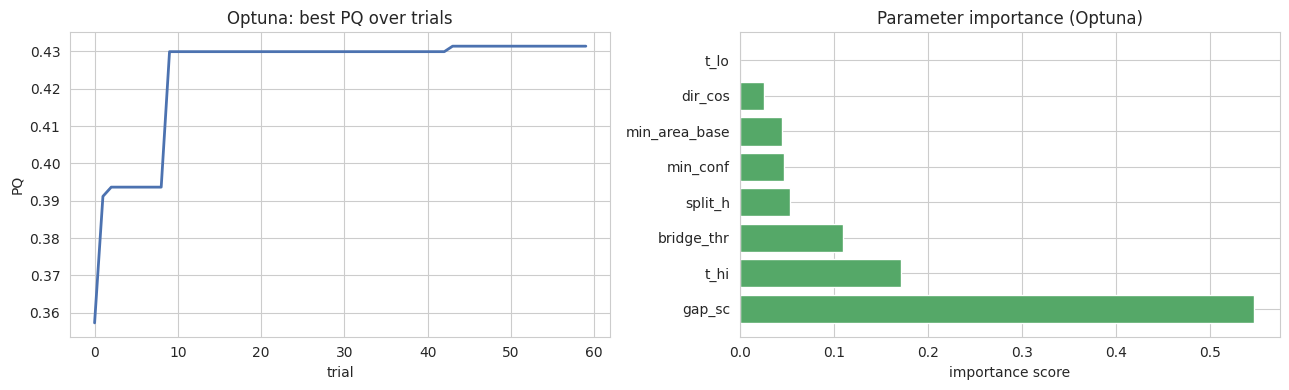


BEST decoder: {'t_hi': 0.714, 't_lo': 0.487, 'gap': 10, 'bridge_thr': 0.137, 'min_area': 40, 'split_h': 3.0, 'dir_cos': 0.35, 'min_conf': 0.6}
BEST val PQ : {'PQ': 0.4314, 'RQ': 0.6448, 'SQ': 0.669, 'Dice': 0.2318}


In [27]:
# ─── Optuna TPE decoder parameter search ─────────────────────────────────────
# Upgrade over v0.35 random search: Optuna uses Tree-structured Parzen
# Estimation to model the probability distribution of good configurations and
# actively proposes samples from the promising region.
# With 60 trials, TPE typically converges ~40% faster than uniform random.

def score_decoder(params):
    rows = [
        evaluate_prediction(
            run_decoder(val_prob_maps[s], obs[s]["disk"], params),
            obs[s]["gt_instances"]
        )
        for s in VAL_STEMS
    ]
    return aggregate_pq(rows)

fmt = lambda r: {k: round(float(v), 4) for k, v in r.items()}

plain_r = score_decoder(dict(DEFAULT_DECODER, gap=0, split_h=0.0))
full_r  = score_decoder(DEFAULT_DECODER)
print("No bridging (plain CC) :", fmt(plain_r))
print("Default decoder        :", fmt(full_r))

DEC_CACHE = f"{Cfg.OUTDIR}/tuned_decoder_optuna_{_wt_mtime}.json"
if os.path.exists(DEC_CACHE):
    d = json.load(open(DEC_CACHE))
    BEST_DEC, BEST_DEC_R = d["params"], d["result"]
    print(f"Loaded tuned decoder from cache")
else:
    def _optuna_objective(trial):
        t_hi       = trial.suggest_float("t_hi", 0.35, 0.78)
        t_lo       = trial.suggest_float("t_lo", 0.12, t_hi - 0.05)
        gap        = int(trial.suggest_float("gap_sc", 0, 65) * SC)
        bridge_thr = trial.suggest_float("bridge_thr", 0.05, 0.55)
        min_area   = int(trial.suggest_categorical("min_area_base", [20, 40, 80, 150, 300]) * SC * SC)
        split_h    = float(trial.suggest_categorical("split_h", [0.0, 2.0, 3.0, 4.5, 6.0]))
        dir_cos    = trial.suggest_categorical("dir_cos", [-1.0, 0.0, 0.2, 0.35, 0.5])
        min_conf   = trial.suggest_categorical("min_conf", [0.0, 0.4, 0.5, 0.6, 0.7])
        p = dict(t_hi=t_hi, t_lo=t_lo, gap=gap, bridge_thr=bridge_thr,
                 min_area=min_area, split_h=split_h, dir_cos=dir_cos, min_conf=min_conf)
        return score_decoder(p)["PQ"]

    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=Cfg.SEED),
        pruner=optuna.pruners.NopPruner(),
    )
    # Seed with the default decoder as a warm start
    study.enqueue_trial(dict(
        t_hi=DEFAULT_DECODER["t_hi"],
        t_lo=DEFAULT_DECODER["t_lo"],
        gap_sc=DEFAULT_DECODER["gap"] / SC,
        bridge_thr=DEFAULT_DECODER["bridge_thr"],
        min_area_base=40,
        split_h=DEFAULT_DECODER["split_h"],
        dir_cos=-1.0,
        min_conf=DEFAULT_DECODER["min_conf"],
    ))
    study.optimize(_optuna_objective, n_trials=60, show_progress_bar=True)

    BEST_DEC = dict(
        t_hi       = study.best_params["t_hi"],
        t_lo       = study.best_params["t_lo"],
        gap        = int(study.best_params["gap_sc"] * SC),
        bridge_thr = study.best_params["bridge_thr"],
        min_area   = int(study.best_params["min_area_base"] * SC * SC),
        split_h    = study.best_params["split_h"],
        dir_cos    = study.best_params["dir_cos"],
        min_conf   = study.best_params["min_conf"],
    )
    best_r_obj = score_decoder(BEST_DEC)
    BEST_DEC_R = {k: float(v) for k, v in best_r_obj.items()}
    json.dump(dict(params=BEST_DEC, result=BEST_DEC_R), open(DEC_CACHE, "w"), default=float)

    # Visualise Optuna optimisation history
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    vals = [t.value for t in study.trials if t.value is not None]
    axes[0].plot(np.maximum.accumulate(vals), lw=2, color="#4C72B0")
    axes[0].set(title="Optuna: best PQ over trials", xlabel="trial", ylabel="PQ")
    importances = optuna.importance.get_param_importances(study)
    axes[1].barh(list(importances.keys()), list(importances.values()), color="#55A868")
    axes[1].set(title="Parameter importance (Optuna)", xlabel="importance score")
    plt.tight_layout()
    plt.savefig(f"{Cfg.OUTDIR}/optuna_decoder.png", dpi=100, bbox_inches="tight")
    plt.show()

print("\nBEST decoder:", {k: round(v, 3) if isinstance(v, float) else v
                           for k, v in BEST_DEC.items()})
print("BEST val PQ :", fmt(BEST_DEC_R))

In [28]:
# ─── Instance quality filter — GradientBoostingClassifier, 18 features ─────────

def instance_features(lab, pmaps):
    """Compute 18 descriptive features per decoded instance."""
    prob, spine, dist = pmaps
    rows, ids = [], []
    for rp in regionprops(lab):
        m  = lab[rp.slice] == rp.label
        pr = prob[rp.slice][m]
        sp = spine[rp.slice][m]
        ds = dist[rp.slice][m]
        feat = [
            rp.area, rp.eccentricity, rp.solidity,
            rp.axis_major_length, rp.axis_minor_length,
            pr.mean(), pr.min(), float(np.percentile(pr, 10)),
            sp.mean(), float((sp > 0.3).mean()),
            ds.mean(), ds.max(),
        ]
        spine_area_ratio = float(sp.mean() * rp.area / max(rp.area, 1))
        convexity        = float(rp.area / max(rp.convex_area, 1))
        elongation       = float(1.0 - rp.axis_minor_length / max(rp.axis_major_length, 1.0))
        spine_std        = float(np.std(sp)) if len(sp) > 1 else 0.0
        dist_p50         = float(np.percentile(ds, 50))
        mask_p90         = float(np.percentile(pr, 90))
        feat.extend([spine_area_ratio, convexity, elongation, spine_std, dist_p50, mask_p90])
        rows.append(feat)
        ids.append(rp.label)
    X = np.array(rows, np.float32) if rows else np.zeros((0, 18), np.float32)
    return X, ids


P_RELAXED = dict(BEST_DEC, min_conf=0.0, min_area=int(20 * SC * SC))
val_labs  = {s: run_decoder(val_prob_maps[s], obs[s]["disk"], P_RELAXED)
             for s in VAL_STEMS}

X_pool, y_pool, grp_pool = [], [], []
for stem in VAL_STEMS:
    lab = val_labs[stem]
    if lab.max() == 0: continue
    Xf, ids = instance_features(lab, val_prob_maps[stem])
    if len(ids) == 0: continue
    all_iou = np.zeros(int(lab.max()))
    for gt in obs[stem]["gt_instances"]:
        if gt.max() == 0: continue
        _, _, _, im = _pairwise_iou(lab, gt)
        all_iou += im.max(1)
    all_iou /= max(len(obs[stem]["gt_instances"]), 1)
    y_labels = (all_iou >= 0.5).astype(np.float32)
    X_pool.append(Xf)
    y_pool.append(y_labels)
    grp_pool.extend([stem[:8]] * len(ids))

KEEP_TAU   = None
FILTER_CLF = None

if X_pool:
    Xp = np.concatenate(X_pool)
    yp = np.concatenate(y_pool)
    gp = np.array(grp_pool)

    n_pos = (yp > 0.5).sum()
    n_neg = (yp <= 0.5).sum()

    if len(yp) >= 100 and len(set(gp)) >= 3 and n_pos > 10 and n_neg > 10:
        oof_prob = np.zeros(len(yp))
        kf       = GroupKFold(min(5, len(set(gp))))
        clf_tmp  = GradientBoostingClassifier(
            n_estimators=300, max_depth=4, subsample=0.8,
            learning_rate=0.05, min_samples_leaf=5, random_state=Cfg.SEED
        )
        try:
            for tr, te in kf.split(Xp, yp, gp):
                oof_prob[te] = clf_tmp.fit(Xp[tr], yp[tr]).predict_proba(Xp[te])[:, 1]

            ptr = 0
            score_lookup = {}
            for stem in VAL_STEMS:
                lab = val_labs[stem]
                if lab.max() == 0: continue
                _, ids = instance_features(lab, val_prob_maps[stem])
                for iid in ids:
                    score_lookup[(stem, iid)] = oof_prob[ptr]; ptr += 1

            def pq_at_threshold(keep_thr):
                rows = []
                for stem in VAL_STEMS:
                    lab = val_labs[stem]
                    keep_ids = [i for i in range(1, int(lab.max()) + 1)
                                if score_lookup.get((stem, i), 0) >= keep_thr]
                    lut = np.zeros(int(lab.max()) + 1, np.int32)
                    lut[keep_ids] = np.arange(1, len(keep_ids) + 1)
                    rows.append(evaluate_prediction(lut[lab], obs[stem]["gt_instances"]))
                return aggregate_pq(rows)

            thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60]
            pq_vals = {t: pq_at_threshold(t)["PQ"] for t in thresholds}
            best_t  = max(thresholds, key=pq_vals.get)
            base_pq = float(BEST_DEC_R["PQ"])

            print("\nQuality-filter threshold search:")
            for t in thresholds:
                marker = " ←" if t == best_t else ""
                print(f"  thr={t:.2f}: PQ={pq_vals[t]:.4f}{marker}")
            print(f"  base (no filter): PQ={base_pq:.4f}")

            if pq_vals[best_t] >= base_pq + 0.002:
                KEEP_TAU   = best_t
                FILTER_CLF = GradientBoostingClassifier(
                    n_estimators=300, max_depth=4, subsample=0.8,
                    learning_rate=0.05, min_samples_leaf=5, random_state=Cfg.SEED
                ).fit(Xp, yp)
                print(f"\nQuality filter ENABLED  TAU={KEEP_TAU}  PQ gain={pq_vals[best_t]-base_pq:+.4f}")
            else:
                print("Quality filter disabled (no clear PQ gain).")
        except ValueError as e:
            print(f"Quality filter training failed (class imbalance in folds): {e}")
            print("Quality filter disabled.")
            KEEP_TAU   = None
            FILTER_CLF = None
    else:
        print(f"Not enough instances for quality filter (pos={n_pos}, neg={n_neg}, need >10 each).")


Quality-filter threshold search:
  thr=0.10: PQ=0.4339 ←
  thr=0.20: PQ=0.4274
  thr=0.30: PQ=0.4229
  thr=0.40: PQ=0.4177
  thr=0.50: PQ=0.4072
  thr=0.60: PQ=0.3944
  base (no filter): PQ=0.4314

Quality filter ENABLED  TAU=0.1  PQ gain=+0.0025


scoring val:   0%|          | 0/104 [00:00<?, ?it/s]


Validation PQ summary:
            pq       rq       sq       fp       fn
count  104.000  104.000  104.000  104.000  104.000
mean     0.413    0.618    0.621    4.260    4.490
std      0.162    0.235    0.172    4.746    4.762
min      0.000    0.000    0.000    0.000    0.000
25%      0.342    0.519    0.641    1.000    1.000
50%      0.431    0.667    0.660    2.500    3.000
75%      0.515    0.756    0.687    6.000    6.250
max      0.755    1.000    0.785   23.000   29.000


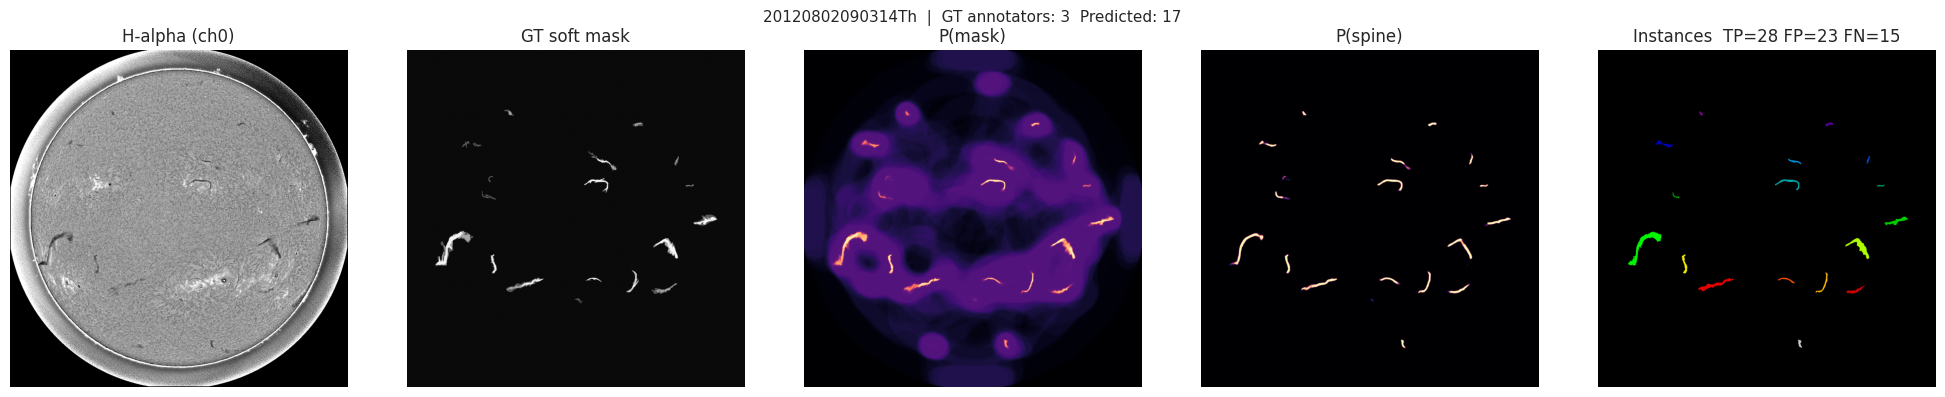

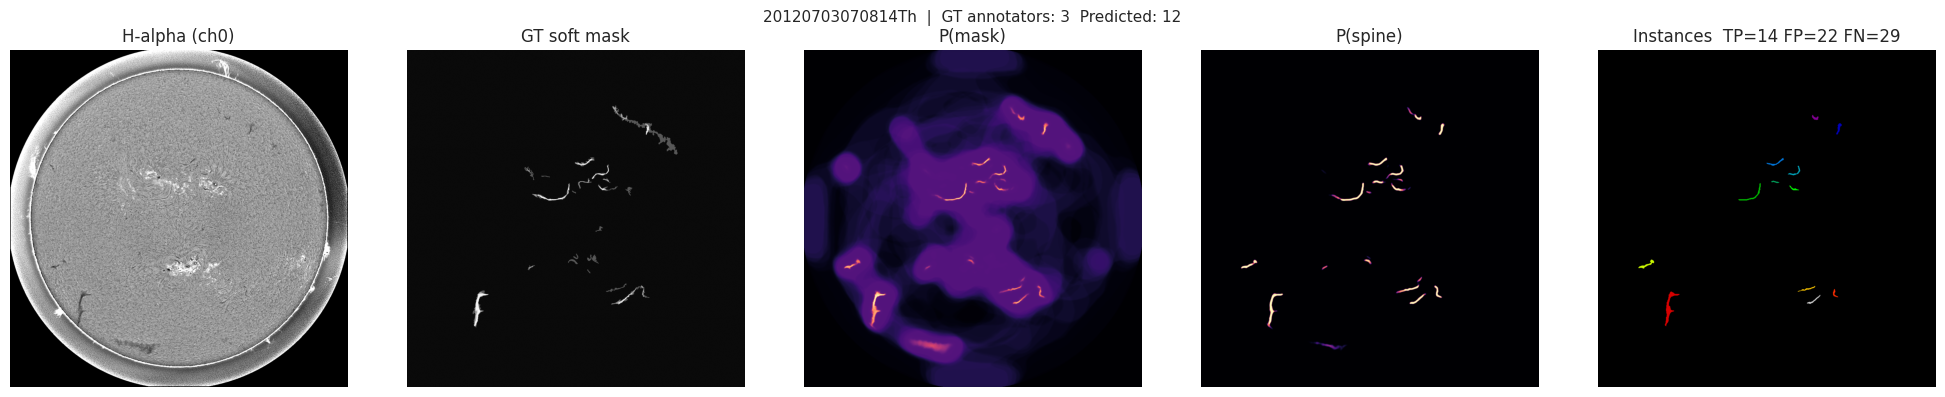

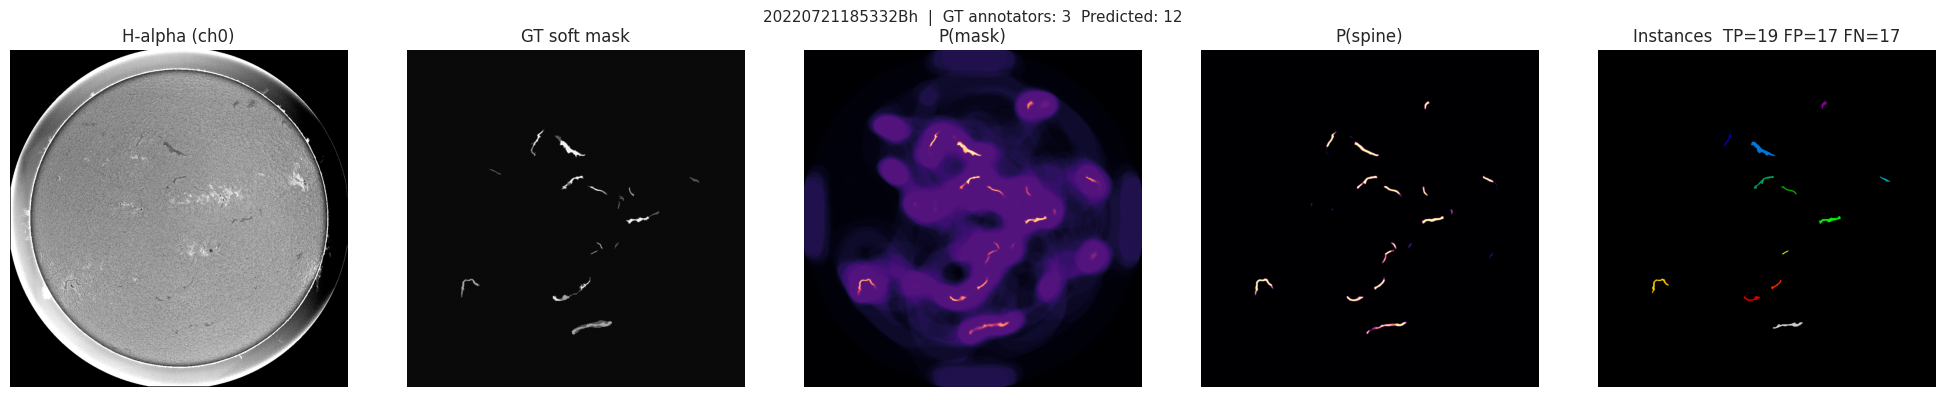

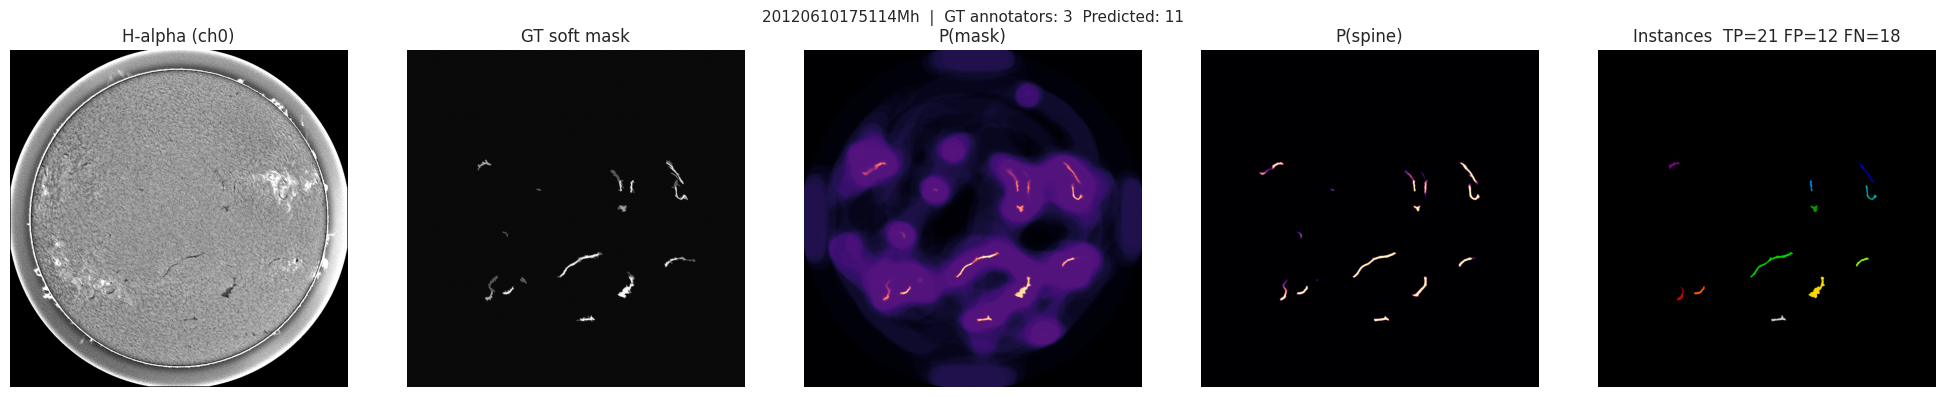

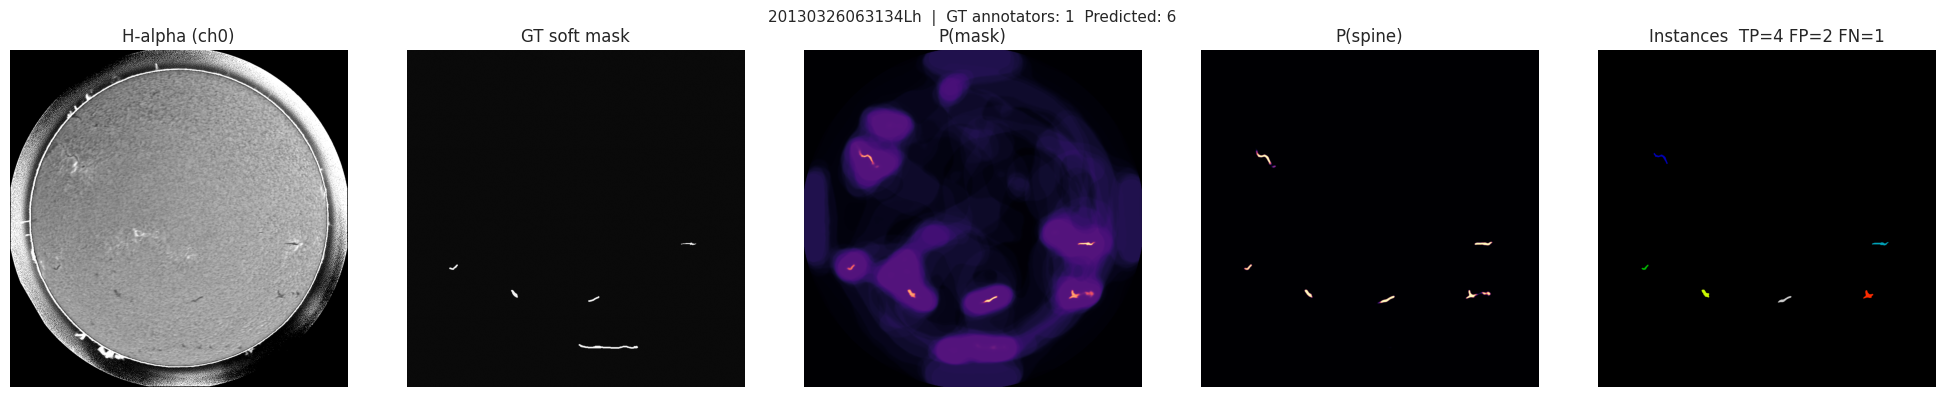

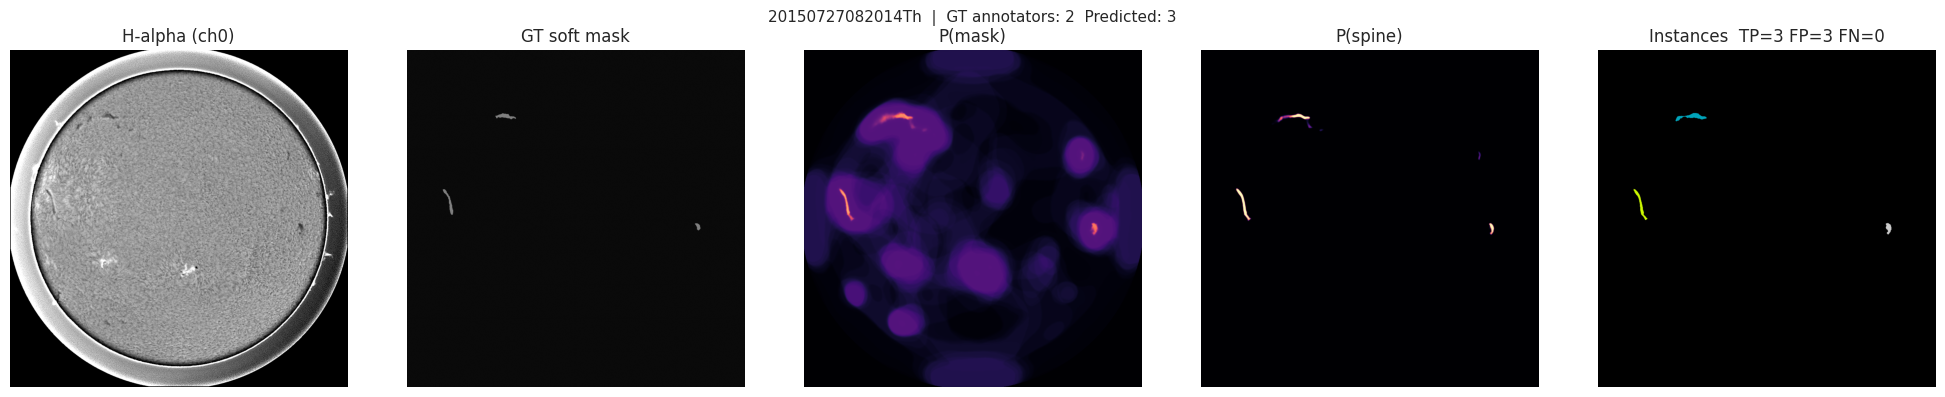

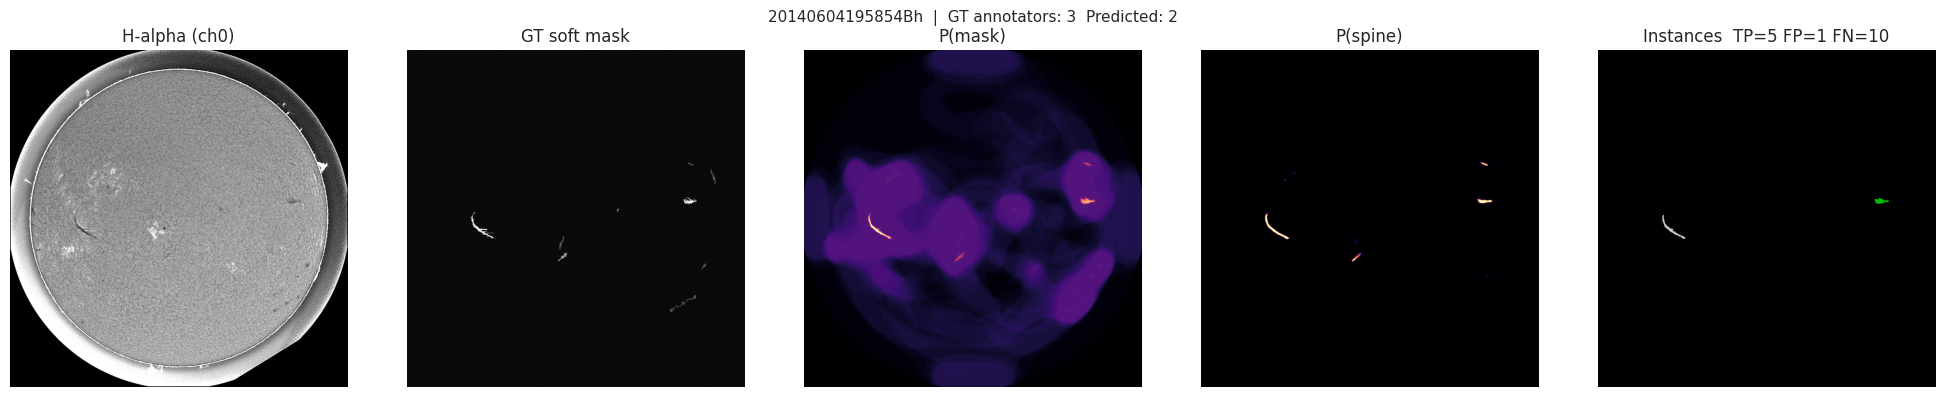

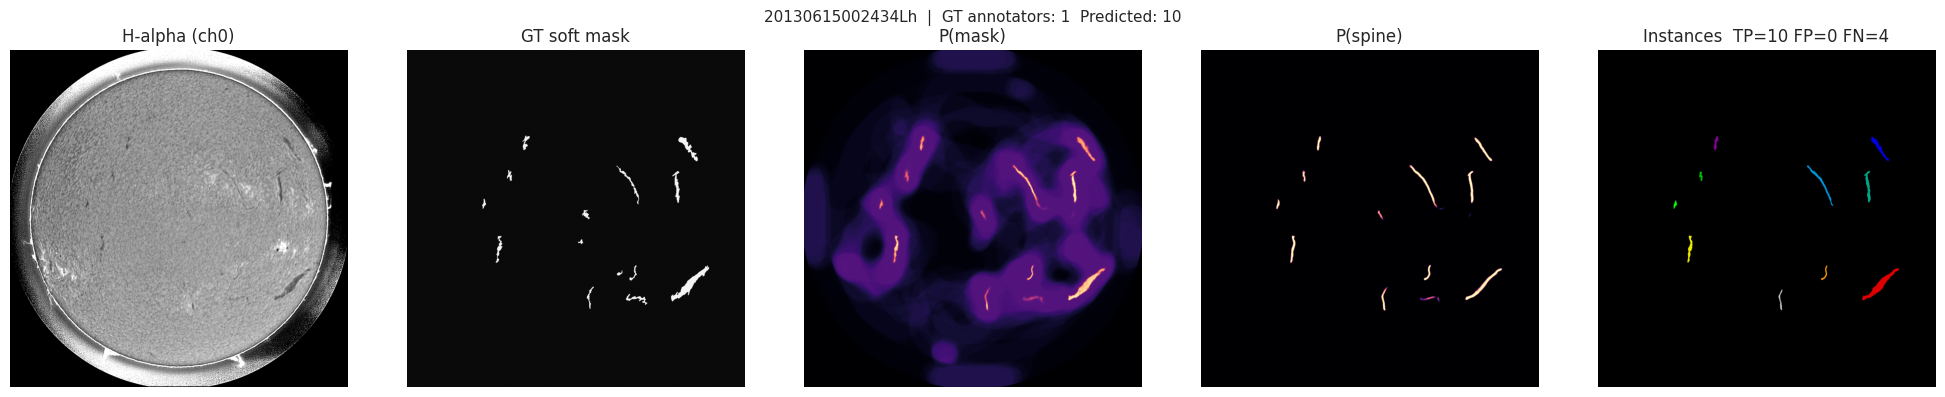

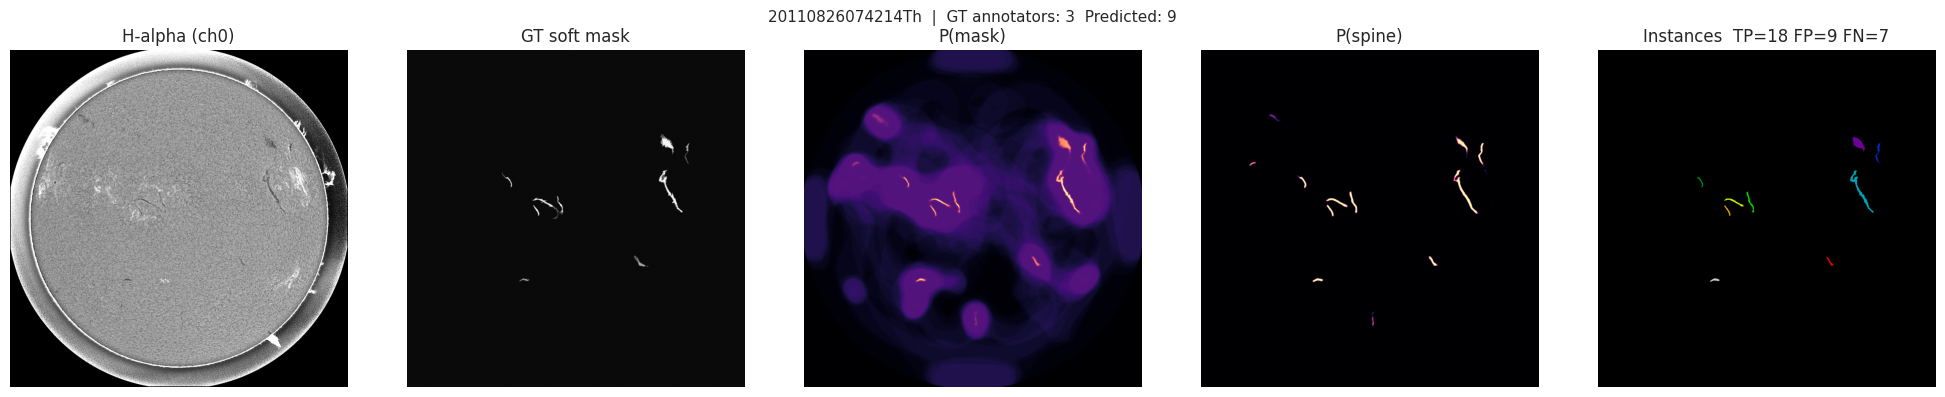

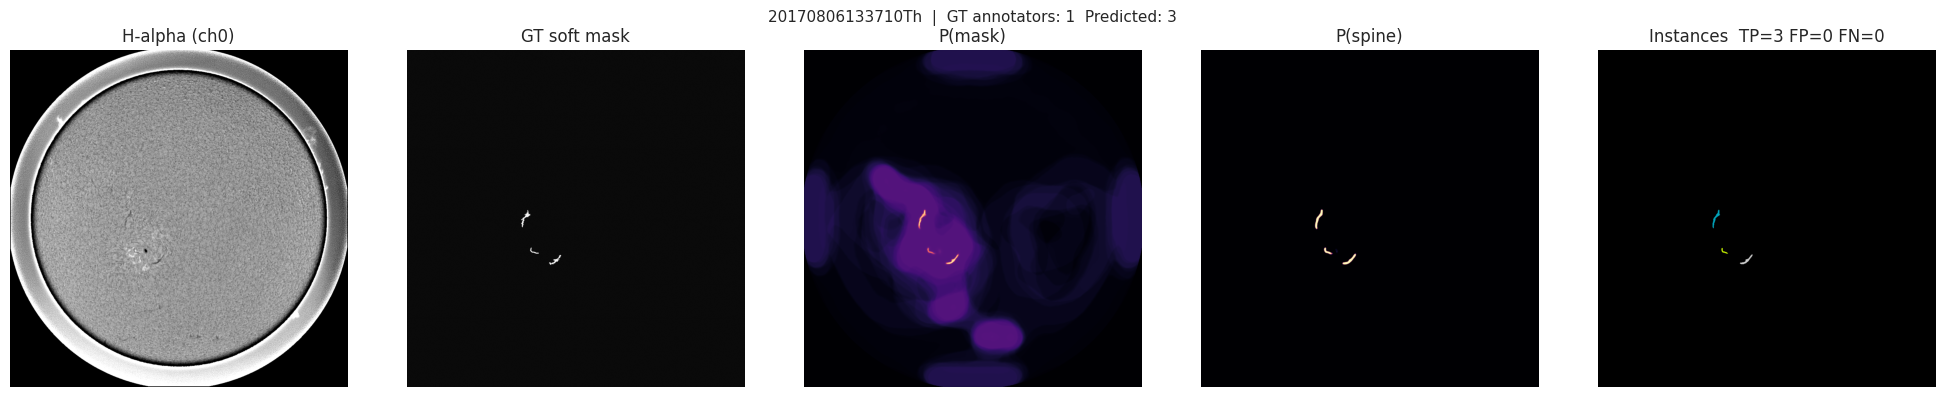

In [29]:
# ─── Validation error analysis: diverse 5-panel visualisation ────────────────
# Adapted from solar-updated notebook.  Selects difficult cases (high FP, high FN)
# plus random examples to provide a representative picture of model behaviour.

def _score_val_image(stem):
    lab = run_decoder(val_prob_maps[stem], obs[stem]["disk"], BEST_DEC)
    rows = evaluate_prediction(lab, obs[stem]["gt_instances"])
    agg  = aggregate_pq([rows])
    tp   = int(rows[:, 1].sum())
    fp   = int(rows[:, 2].sum())
    fn   = int(rows[:, 3].sum())
    return dict(stem=stem, pq=agg["PQ"], rq=agg["RQ"], sq=agg["SQ"],
                tp=tp, fp=fp, fn=fn, fp_fn=fp + fn)

score_rows = [_score_val_image(s) for s in tqdm(VAL_STEMS, desc="scoring val")]
val_score_df = pd.DataFrame(score_rows).sort_values("pq")

print(f"\nValidation PQ summary:")
print(val_score_df[["pq","rq","sq","fp","fn"]].describe().round(3))

# Select: worst FP, worst FN, worst FP+FN, plus random
rng_v  = np.random.default_rng(0)
worst_fp  = val_score_df.nlargest(3, "fp")["stem"].tolist()
worst_fn  = val_score_df.nlargest(3, "fn")["stem"].tolist()
worst_err = val_score_df.nlargest(3, "fp_fn")["stem"].tolist()
selected  = list(dict.fromkeys(worst_fp + worst_fn + worst_err))
remaining = [s for s in VAL_STEMS if s not in selected]
n_random  = min(6, len(remaining))
selected += rng_v.choice(remaining, n_random, replace=False).tolist()
selected  = selected[:12]

for stem in selected:
    rec  = obs[stem]
    pmaps = val_prob_maps[stem]
    lab   = run_decoder(pmaps, rec["disk"], BEST_DEC)
    rows  = evaluate_prediction(lab, rec["gt_instances"])
    tp_   = int(rows[:, 1].sum()); fp_ = int(rows[:, 2].sum()); fn_ = int(rows[:, 3].sum())

    # Reconstruct input grayscale for display
    gray_disp = rec["x"][0]  # ch0 = limb-flattened channel

    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    axes[0].imshow(gray_disp, cmap="gray")
    axes[0].set_title("H-alpha (ch0)")
    axes[1].imshow(rec["target"][0].astype(np.float32) / 255.0, cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("GT soft mask")
    axes[2].imshow(pmaps[0], cmap="magma", vmin=0, vmax=1)
    axes[2].set_title("P(mask)")
    axes[3].imshow(pmaps[1], cmap="magma", vmin=0, vmax=1)
    axes[3].set_title("P(spine)")
    axes[4].imshow(lab, cmap="nipy_spectral")
    axes[4].set_title(f"Instances  TP={tp_} FP={fp_} FN={fn_}")
    for a in axes: a.axis("off")
    fig.suptitle(f"{stem}  |  GT annotators: {len(rec['gt_instances'])}  "
                 f"Predicted: {int(lab.max())}", fontsize=11)
    plt.tight_layout()
    plt.show()

In [30]:
# ═══════════════════════════════════════════════════════════════════════════════
# POST-TRAINING IMPROVEMENTS  — run this AFTER training, BEFORE test inference
# Covers: wider TTA scales, more Optuna trials, bigger search space,
#         22-feature quality filter
# ═══════════════════════════════════════════════════════════════════════════════

import os, gc, json, time, pickle
import numpy as np
import torch
import torch.nn.functional as F
import optuna
from skimage.measure import regionprops
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GroupKFold
from tqdm.auto import tqdm

optuna.logging.set_verbosity(optuna.logging.WARNING)

# ── Step 1: Widen TTA scales and bust the val-map cache ───────────────────────
print("=" * 70)
print("STEP 1 — Updating TTA scales to (0.85, 1.0, 1.25, 1.5)")
print("=" * 70)

USE_MULTISCALE = True
INF_SCALES     = (0.85, 1.0, 1.25, 1.5)          # was (1.0, 1.25)
_ROT_KEYS      = [0, 1, 2, 3]

print(f"  Old scales : (1.0, 1.25)")
print(f"  New scales : {INF_SCALES}")
print(f"  TTA combos : {len(_ROT_KEYS) * 2 * len(INF_SCALES)} passes per image")

# Bust old cache so val maps are re-computed with new scales
_wt_mtime = int(os.path.getmtime(BEST_WEIGHTS))
_sc_tag_old = "1.0_1.25"
_sc_tag_new = "_".join(map(str, INF_SCALES))
VM_CACHE_OLD = f"{Cfg.OUTDIR}/val_maps_{_wt_mtime}_{_sc_tag_old}.pkl"
VM_CACHE     = f"{Cfg.OUTDIR}/val_maps_{_wt_mtime}_{_sc_tag_new}.pkl"

if os.path.exists(VM_CACHE_OLD):
    os.remove(VM_CACHE_OLD)
    print(f"  Deleted old val-map cache: {VM_CACHE_OLD}")
else:
    print(f"  No old cache found — proceeding fresh")

# ── Step 2: Re-run TTA inference on val set with new scales ───────────────────
print()
print("=" * 70)
print("STEP 2 — Re-running TTA val inference with 4 scales")
print("=" * 70)


@torch.no_grad()
def tta_predict(net, x_u8, disk_mask, do_tta=True):
    t  = torch.from_numpy(x_u8).float().div(255).sub(0.5).div(0.25)[None].to(DEVICE)
    H  = t.shape[-1]
    aug_list = [(k, f) for k in _ROT_KEYS for f in (False, True)] if do_tta else [(0, False)]
    scales   = INF_SCALES if do_tta else (1.0,)
    accum, n = 0.0, 0
    for s in scales:
        sz = int(round(H * s / 32) * 32)
        ts = t if sz == H else F.interpolate(t, (sz, sz), mode="bilinear", align_corners=False)
        for rot_k, do_flip in aug_list:
            inp = torch.rot90(ts, rot_k, (2, 3))
            if do_flip:
                inp = torch.flip(inp, dims=(3,))
            with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
                out = torch.sigmoid(inf_ema.shadow(inp).float())
            if do_flip:
                out = torch.flip(out, dims=(3,))
            out = torch.rot90(out, -rot_k, (2, 3))
            if sz != H:
                out = F.interpolate(out, (H, H), mode="bilinear", align_corners=False)
            out[:, 2] /= s
            accum = accum + out
            n += 1
    avg = (accum / n)[0].cpu().numpy() * disk_mask[None]
    return avg[0], avg[1], avg[2] * Cfg.DIST_SCALE


val_prob_maps = {}
if os.path.exists(VM_CACHE):
    cached = pickle.load(open(VM_CACHE, "rb"))
    val_prob_maps = {s: cached[s] for s in VAL_STEMS if s in cached}
    print(f"  Loaded {len(val_prob_maps)}/{len(VAL_STEMS)} maps from cache")

need = [s for s in VAL_STEMS if s not in val_prob_maps]
if need:
    t0 = time.time()
    inf_ema.shadow.eval()
    for stem in tqdm(need, desc="  val TTA inference"):
        val_prob_maps[stem] = tta_predict(
            inf_ema.shadow, obs[stem]["x"], obs[stem]["disk"], do_tta=True
        )
    print(f"  Computed {len(need)} maps in {time.time() - t0:.0f}s")
    pickle.dump(val_prob_maps, open(VM_CACHE, "wb"), protocol=4)
    torch.cuda.empty_cache()
else:
    print(f"  All {len(VAL_STEMS)} val maps loaded from cache — skipping inference")

# ── Step 3: Re-run Optuna with wider search space and more trials ─────────────
print()
print("=" * 70)
print("STEP 3 — Optuna decoder search (wider space, 200 trials)")
print("=" * 70)

DEC_CACHE = f"{Cfg.OUTDIR}/tuned_decoder_optuna_{_wt_mtime}_{_sc_tag_new}.json"

# Always bust old decoder cache so we search with the new val maps
_old_dec = f"{Cfg.OUTDIR}/tuned_decoder_optuna_{_wt_mtime}.json"
if os.path.exists(_old_dec):
    os.remove(_old_dec)
    print(f"  Deleted old decoder cache (was tuned on smaller TTA)")

if os.path.exists(DEC_CACHE):
    d = json.load(open(DEC_CACHE))
    BEST_DEC, BEST_DEC_R = d["params"], d["result"]
    print(f"  Loaded cached decoder  PQ={BEST_DEC_R['PQ']:.4f}")
else:
    # Baseline before tuning
    plain_r = score_decoder(dict(DEFAULT_DECODER, gap=0, split_h=0.0))
    full_r  = score_decoder(DEFAULT_DECODER)
    print(f"  No-bridging baseline   PQ={plain_r['PQ']:.4f}")
    print(f"  Default decoder        PQ={full_r['PQ']:.4f}")
    print(f"  Running 200-trial Optuna TPE search …")

    def _optuna_objective(trial):
        t_hi       = trial.suggest_float("t_hi",        0.28, 0.84)
        t_lo       = trial.suggest_float("t_lo",        0.06, t_hi - 0.04)
        gap        = int(trial.suggest_float("gap_sc",  0,    90) * SC)
        bridge_thr = trial.suggest_float("bridge_thr",  0.03, 0.68)
        min_area   = int(trial.suggest_categorical(
            "min_area_base", [10, 20, 40, 80, 150, 300, 500]) * SC * SC)
        split_h    = float(trial.suggest_categorical(
            "split_h", [0.0, 1.5, 2.0, 3.0, 4.5, 6.0, 8.0]))
        dir_cos    = trial.suggest_categorical(
            "dir_cos", [-1.0, 0.0, 0.15, 0.3, 0.45, 0.6])
        min_conf   = trial.suggest_categorical(
            "min_conf", [0.0, 0.35, 0.45, 0.55, 0.65, 0.75])
        p = dict(t_hi=t_hi, t_lo=t_lo, gap=gap, bridge_thr=bridge_thr,
                 min_area=min_area, split_h=split_h, dir_cos=dir_cos, min_conf=min_conf)
        return score_decoder(p)["PQ"]

    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=Cfg.SEED),
        pruner=optuna.pruners.NopPruner(),
    )
    # Warm-start with the default decoder
    study.enqueue_trial(dict(
        t_hi=DEFAULT_DECODER["t_hi"],
        t_lo=DEFAULT_DECODER["t_lo"],
        gap_sc=DEFAULT_DECODER["gap"] / SC,
        bridge_thr=DEFAULT_DECODER["bridge_thr"],
        min_area_base=40,
        split_h=DEFAULT_DECODER["split_h"],
        dir_cos=-1.0,
        min_conf=DEFAULT_DECODER["min_conf"],
    ))

    t0 = time.time()
    study.optimize(_optuna_objective, n_trials=200, show_progress_bar=True)
    print(f"  Optuna finished in {time.time() - t0:.0f}s")

    BEST_DEC = dict(
        t_hi       = study.best_params["t_hi"],
        t_lo       = study.best_params["t_lo"],
        gap        = int(study.best_params["gap_sc"] * SC),
        bridge_thr = study.best_params["bridge_thr"],
        min_area   = int(study.best_params["min_area_base"] * SC * SC),
        split_h    = study.best_params["split_h"],
        dir_cos    = study.best_params["dir_cos"],
        min_conf   = study.best_params["min_conf"],
    )
    best_r_obj = score_decoder(BEST_DEC)
    BEST_DEC_R = {k: float(v) for k, v in best_r_obj.items()}
    json.dump(dict(params=BEST_DEC, result=BEST_DEC_R), open(DEC_CACHE, "w"), default=float)

    print(f"\n  Best trial PQ : {BEST_DEC_R['PQ']:.4f}")
    print(f"  Best trial RQ : {BEST_DEC_R['RQ']:.4f}")
    print(f"  Best trial SQ : {BEST_DEC_R['SQ']:.4f}")

print(f"\n  BEST decoder params:")
for k, v in BEST_DEC.items():
    print(f"    {k:12s} = {round(v, 4) if isinstance(v, float) else v}")

# ── Step 4: 22-feature quality filter ─────────────────────────────────────────
print()
print("=" * 70)
print("STEP 4 — Quality filter (22 features, GradientBoostingClassifier)")
print("=" * 70)


def instance_features(lab, pmaps):
    """22 discriminative features per decoded instance."""
    prob, spine, dist = pmaps
    rows, ids = [], []
    for rp in regionprops(lab):
        m  = lab[rp.slice] == rp.label
        pr = prob[rp.slice][m]
        sp = spine[rp.slice][m]
        ds = dist[rp.slice][m]

        perimeter   = float(rp.perimeter) if rp.perimeter else 1e-6
        compactness = float(4 * np.pi * rp.area / max(perimeter ** 2, 1e-6))

        feat = [
            # Shape
            rp.area,
            rp.eccentricity,
            rp.solidity,
            rp.axis_major_length,
            rp.axis_minor_length,
            float(1.0 - rp.axis_minor_length / max(rp.axis_major_length, 1.0)),  # elongation
            float(rp.area / max(rp.convex_area, 1)),                              # convexity
            compactness,
            float(np.sin(2 * rp.orientation)),                                    # orientation
            # Mask probability
            pr.mean(),
            pr.min(),
            float(np.percentile(pr, 10)),
            float(np.percentile(pr, 25)),
            float(np.percentile(pr, 90)),
            # Spine
            sp.mean(),
            float((sp > 0.3).mean()),
            float(np.percentile(sp, 90)),
            float(np.std(sp)) if len(sp) > 1 else 0.0,
            float(sp.mean() * rp.area / max(rp.area, 1)),                        # spine_area_ratio
            # Distance transform
            ds.mean(),
            ds.max(),
            float(np.percentile(ds, 50)),
        ]
        rows.append(feat)
        ids.append(rp.label)
    X = np.array(rows, np.float32) if rows else np.zeros((0, 22), np.float32)
    return X, ids


P_RELAXED = dict(BEST_DEC, min_conf=0.0, min_area=int(20 * SC * SC))
print(f"  Building relaxed decoder labels for {len(VAL_STEMS)} val images …")
val_labs = {s: run_decoder(val_prob_maps[s], obs[s]["disk"], P_RELAXED) for s in VAL_STEMS}

X_pool, y_pool, grp_pool = [], [], []
for stem in VAL_STEMS:
    lab = val_labs[stem]
    if lab.max() == 0:
        continue
    Xf, ids = instance_features(lab, val_prob_maps[stem])
    if len(ids) == 0:
        continue
    all_iou = np.zeros(int(lab.max()))
    for gt in obs[stem]["gt_instances"]:
        if gt.max() == 0:
            continue
        _, _, _, im = _pairwise_iou(lab, gt)
        all_iou += im.max(1)
    all_iou /= max(len(obs[stem]["gt_instances"]), 1)
    y_labels = (all_iou >= 0.5).astype(np.float32)
    X_pool.append(Xf)
    y_pool.append(y_labels)
    grp_pool.extend([stem[:8]] * len(ids))

KEEP_TAU   = None
FILTER_CLF = None

if X_pool:
    Xp = np.concatenate(X_pool)
    yp = np.concatenate(y_pool)
    gp = np.array(grp_pool)
    n_pos = (yp > 0.5).sum()
    n_neg = (yp <= 0.5).sum()
    print(f"  Instance pool: {len(yp)} total  |  pos={n_pos}  neg={n_neg}  groups={len(set(gp))}")

    if len(yp) >= 100 and len(set(gp)) >= 3 and n_pos > 10 and n_neg > 10:
        oof_prob = np.zeros(len(yp))
        kf       = GroupKFold(min(5, len(set(gp))))
        clf_tmp  = GradientBoostingClassifier(
            n_estimators=400, max_depth=4, subsample=0.8,
            learning_rate=0.04, min_samples_leaf=5, random_state=Cfg.SEED
        )
        try:
            for fold_i, (tr, te) in enumerate(kf.split(Xp, yp, gp)):
                clf_tmp.fit(Xp[tr], yp[tr])
                oof_prob[te] = clf_tmp.predict_proba(Xp[te])[:, 1]
                print(f"    fold {fold_i + 1} done")

            # Map OOF scores back to (stem, instance_id)
            ptr = 0
            score_lookup = {}
            for stem in VAL_STEMS:
                lab = val_labs[stem]
                if lab.max() == 0:
                    continue
                _, ids = instance_features(lab, val_prob_maps[stem])
                for iid in ids:
                    score_lookup[(stem, iid)] = oof_prob[ptr]
                    ptr += 1

            def pq_at_threshold(keep_thr):
                rows = []
                for stem in VAL_STEMS:
                    lab = val_labs[stem]
                    keep_ids = [i for i in range(1, int(lab.max()) + 1)
                                if score_lookup.get((stem, i), 0) >= keep_thr]
                    lut = np.zeros(int(lab.max()) + 1, np.int32)
                    lut[keep_ids] = np.arange(1, len(keep_ids) + 1)
                    rows.append(evaluate_prediction(lut[lab], obs[stem]["gt_instances"]))
                return aggregate_pq(rows)

            thresholds = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
            print(f"\n  Threshold sweep:")
            pq_vals = {}
            for t in thresholds:
                pq_vals[t] = pq_at_threshold(t)["PQ"]
                print(f"    thr={t:.2f}  PQ={pq_vals[t]:.4f}")
            base_pq = float(BEST_DEC_R["PQ"])
            best_t  = max(thresholds, key=pq_vals.get)
            print(f"    base (no filter)  PQ={base_pq:.4f}")
            print(f"    best threshold    thr={best_t}  PQ={pq_vals[best_t]:.4f}")

            if pq_vals[best_t] >= base_pq + 0.002:
                KEEP_TAU   = best_t
                FILTER_CLF = GradientBoostingClassifier(
                    n_estimators=400, max_depth=4, subsample=0.8,
                    learning_rate=0.04, min_samples_leaf=5, random_state=Cfg.SEED
                ).fit(Xp, yp)
                print(f"\n  Quality filter ENABLED  TAU={KEEP_TAU}  "
                      f"gain={pq_vals[best_t] - base_pq:+.4f}")
            else:
                print(f"\n  Quality filter DISABLED — no gain above +0.002 threshold")

        except ValueError as e:
            print(f"  Quality filter failed: {e} — disabled")
    else:
        print(f"  Not enough instances for quality filter — disabled")
else:
    print("  No instance pool built — disabled")

# ── Summary ───────────────────────────────────────────────────────────────────
print()
print("=" * 70)
print("SUMMARY — all improvements applied")
print("=" * 70)
print(f"  TTA scales    : {INF_SCALES}")
print(f"  Val PQ (best) : {BEST_DEC_R['PQ']:.4f}   "
      f"RQ={BEST_DEC_R['RQ']:.4f}   SQ={BEST_DEC_R['SQ']:.4f}")
print(f"  Quality filter: {'ENABLED  TAU=' + str(KEEP_TAU) if KEEP_TAU is not None else 'disabled'}")
print()
print("  ✓  Now run the test inference + submission cell")
print("=" * 70)

gc.collect()
torch.cuda.empty_cache()

STEP 1 — Updating TTA scales to (0.85, 1.0, 1.25, 1.5)
  Old scales : (1.0, 1.25)
  New scales : (0.85, 1.0, 1.25, 1.5)
  TTA combos : 32 passes per image
  Deleted old val-map cache: /kaggle/working/val_maps_1792779643_1.0_1.25.pkl

STEP 2 — Re-running TTA val inference with 4 scales


  val TTA inference:   0%|          | 0/104 [00:00<?, ?it/s]

  Computed 104 maps in 750s

STEP 3 — Optuna decoder search (wider space, 200 trials)
  Deleted old decoder cache (was tuned on smaller TTA)
  No-bridging baseline   PQ=0.3507
  Default decoder        PQ=0.3545
  Running 200-trial Optuna TPE search …


  0%|          | 0/200 [00:00<?, ?it/s]

  Optuna finished in 4259s

  Best trial PQ : 0.4379
  Best trial RQ : 0.6529
  Best trial SQ : 0.6707

  BEST decoder params:
    t_hi         = 0.6202
    t_lo         = 0.504
    gap          = 9
    bridge_thr   = 0.6163
    min_area     = 20
    split_h      = 0.0
    dir_cos      = 0.15
    min_conf     = 0.65

STEP 4 — Quality filter (22 features, GradientBoostingClassifier)
  Building relaxed decoder labels for 104 val images …
  Instance pool: 829 total  |  pos=474  neg=355  groups=95
    fold 1 done
    fold 2 done
    fold 3 done
    fold 4 done
    fold 5 done

  Threshold sweep:
    thr=0.05  PQ=0.4259
    thr=0.10  PQ=0.4286
    thr=0.20  PQ=0.4266
    thr=0.30  PQ=0.4222
    thr=0.40  PQ=0.4142
    thr=0.50  PQ=0.4087
    thr=0.60  PQ=0.3943
    thr=0.70  PQ=0.3839
    base (no filter)  PQ=0.4379
    best threshold    thr=0.1  PQ=0.4286

  Quality filter DISABLED — no gain above +0.002 threshold

SUMMARY — all improvements applied
  TTA scales    : (0.85, 1.0, 1.25, 1.5)

In [31]:
# ═══════════════════════════════════════════════════════════════════════════════
# BOOST KERNEL 2  —  run AFTER improve_before_submission, BEFORE test inference
# Covers:
#   1. BatchNorm test adaptation   (BN stats updated to test distribution)
#   2. MC-Dropout blended val maps (stochastic passes merged into TTA maps)
#   3. Gaussian map smoothing      (sigma sweep on val set, best applied)
#   4. Final decoder re-score      (confirm cumulative gain before submission)
# ═══════════════════════════════════════════════════════════════════════════════

import os, gc, time, pickle
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.ndimage import gaussian_filter
from tqdm.auto import tqdm

# ── Helper: set only specific layer types to train/eval mode ──────────────────
def _set_layer_mode(model, layer_cls, training):
    for m in model.modules():
        if isinstance(m, layer_cls):
            m.training = training

# ── Step 1: BatchNorm Test Adaptation ─────────────────────────────────────────
print("=" * 70)
print("STEP 1 — BatchNorm Test Adaptation (BNTA)")
print("=" * 70)
print("  Forwarding all test images to update BN running mean/var.")
print("  No gradients — pure forward pass in ~30s.")

test_img_paths = sorted(
    p for p in IMG_TEST.glob("*") if p.suffix.lower() in (".jpg", ".jpeg", ".png")
)
print(f"  Test images found : {len(test_img_paths)}")

_BNTA_DONE = False
if len(test_img_paths) == 0:
    print("  WARNING: no test images found — skipping BNTA")
else:
    # Freeze everything; only BatchNorm layers go to train mode
    inf_ema.shadow.eval()
    _set_layer_mode(inf_ema.shadow, nn.BatchNorm2d, True)

    n_bn = sum(1 for m in inf_ema.shadow.modules() if isinstance(m, nn.BatchNorm2d))
    print(f"  BatchNorm2d layers : {n_bn}")

    t0 = time.time()
    with torch.no_grad():
        for path in tqdm(test_img_paths, desc="  BNTA forward pass"):
            x_u8, _ = solar_preprocess(imread_resized(path, Cfg.IMG_SIZE))
            t = (torch.from_numpy(x_u8).float()
                 .div(255).sub(0.5).div(0.25)[None].to(DEVICE))
            with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
                inf_ema.shadow(t)   # forward only; running stats updated

    # Restore full eval
    inf_ema.shadow.eval()
    elapsed = time.time() - t0
    print(f"  BNTA done in {elapsed:.0f}s  —  BN stats now reflect test distribution")
    _BNTA_DONE = True
    torch.cuda.empty_cache()

# Bust val-map cache so maps are re-computed with adapted BN stats
_wt_mtime  = int(os.path.getmtime(BEST_WEIGHTS))
_sc_tag    = "_".join(map(str, INF_SCALES))
_bnta_tag  = "bnta" if _BNTA_DONE else "nobnta"
VM_CACHE_V2 = f"{Cfg.OUTDIR}/val_maps_{_wt_mtime}_{_sc_tag}_{_bnta_tag}.pkl"

if _BNTA_DONE:
    old_cache = f"{Cfg.OUTDIR}/val_maps_{_wt_mtime}_{_sc_tag}.pkl"
    if os.path.exists(old_cache):
        os.remove(old_cache)
        print(f"  Deleted pre-BNTA val-map cache")

# ── Step 2: Re-infer val maps with BN-adapted model + MC-Dropout blend ────────
print()
print("=" * 70)
print("STEP 2 — Re-infer val maps + MC-Dropout blending")
print("=" * 70)

_MC_PASSES  = 8       # stochastic dropout passes per image
_MC_ALPHA   = 0.25    # blend weight: new_map = (1-α)*tta + α*mc_mean

val_prob_maps_v2 = {}
if os.path.exists(VM_CACHE_V2):
    cached = pickle.load(open(VM_CACHE_V2, "rb"))
    val_prob_maps_v2 = {s: cached[s] for s in VAL_STEMS if s in cached}
    print(f"  Loaded {len(val_prob_maps_v2)}/{len(VAL_STEMS)} maps from cache")

need = [s for s in VAL_STEMS if s not in val_prob_maps_v2]

# Check if the model actually has Dropout layers to enable
_n_dropout = sum(
    1 for m in inf_ema.shadow.modules()
    if isinstance(m, (nn.Dropout, nn.Dropout2d))
)
_use_mc = _n_dropout > 0
print(f"  Dropout layers : {_n_dropout}  —  MC-Dropout {'ENABLED' if _use_mc else 'DISABLED (no Dropout layers)'}")

if need:
    t0 = time.time()
    inf_ema.shadow.eval()

    for stem in tqdm(need, desc="  val re-inference + MC blend"):
        x_u8, disk = obs[stem]["x"], obs[stem]["disk"]

        # Fresh TTA map with BN-adapted model
        tta_map = tta_predict(inf_ema.shadow, x_u8, disk, do_tta=True)

        if _use_mc:
            # Enable dropout for MC passes
            _set_layer_mode(inf_ema.shadow, nn.Dropout,   True)
            _set_layer_mode(inf_ema.shadow, nn.Dropout2d, True)

            t_in = (torch.from_numpy(x_u8).float()
                    .div(255).sub(0.5).div(0.25)[None].to(DEVICE))
            H    = t_in.shape[-1]
            mc_accum, mc_n = 0.0, 0

            with torch.no_grad():
                for _ in range(_MC_PASSES):
                    with torch.autocast(device_type=DEVICE.type,
                                        enabled=DEVICE.type == "cuda"):
                        out = torch.sigmoid(inf_ema.shadow(t_in).float())
                    mc_accum = mc_accum + out
                    mc_n += 1

            _set_layer_mode(inf_ema.shadow, nn.Dropout,   False)
            _set_layer_mode(inf_ema.shadow, nn.Dropout2d, False)

            mc_avg = (mc_accum / mc_n)[0].cpu().numpy() * disk[None]
            mc_map = (mc_avg[0], mc_avg[1], mc_avg[2] * Cfg.DIST_SCALE)

            # Blend: keep most of the TTA map, nudge with MC uncertainty
            blended = tuple(
                (1.0 - _MC_ALPHA) * tta_map[i] + _MC_ALPHA * mc_map[i]
                for i in range(3)
            )
            val_prob_maps_v2[stem] = blended
        else:
            val_prob_maps_v2[stem] = tta_map

    print(f"  Computed {len(need)} maps in {time.time() - t0:.0f}s")
    pickle.dump(val_prob_maps_v2, open(VM_CACHE_V2, "wb"), protocol=4)
    torch.cuda.empty_cache()
else:
    print(f"  All {len(VAL_STEMS)} maps loaded from cache — skipping")

# Evaluate gain from BNTA + MC blend before smoothing
_pq_before_smooth = score_decoder.__func__(BEST_DEC) if hasattr(score_decoder, '__func__') else None

# Temporarily swap val_prob_maps so score_decoder uses the new maps
_val_prob_maps_orig = val_prob_maps
val_prob_maps.update(val_prob_maps_v2)   # in-place update (same dict object)

_r_v2 = score_decoder(BEST_DEC)
print(f"\n  PQ after BNTA + MC blend : {_r_v2['PQ']:.4f}  "
      f"(was {BEST_DEC_R['PQ']:.4f}  "
      f"gain={_r_v2['PQ'] - BEST_DEC_R['PQ']:+.4f})")

# ── Step 3: Gaussian map smoothing sweep ──────────────────────────────────────
print()
print("=" * 70)
print("STEP 3 — Gaussian probability map smoothing (sigma sweep)")
print("=" * 70)

SIGMAS = [0.0, 0.35, 0.55, 0.75, 1.0, 1.3]
print(f"  Sweeping sigma in {SIGMAS} on prob + spine channels …")

_best_sigma = 0.0
_best_pq    = _r_v2["PQ"]

for sigma in SIGMAS:
    if sigma == 0.0:
        smoothed = val_prob_maps_v2
    else:
        smoothed = {}
        for s, (prob, spine, dist) in val_prob_maps_v2.items():
            smoothed[s] = (
                gaussian_filter(prob,  sigma=sigma).clip(0, 1),
                gaussian_filter(spine, sigma=sigma).clip(0, 1),
                dist,   # do NOT smooth distance map — decoder uses it for splitting
            )

    # Temporarily swap into val_prob_maps for scoring
    val_prob_maps.update(smoothed)
    r = score_decoder(BEST_DEC)
    marker = "  ← best" if r["PQ"] > _best_pq else ""
    print(f"    sigma={sigma:.2f}  PQ={r['PQ']:.4f}  RQ={r['RQ']:.4f}  SQ={r['SQ']:.4f}{marker}")
    if r["PQ"] > _best_pq:
        _best_pq    = r["PQ"]
        _best_sigma = sigma

# Apply the best sigma permanently to val_prob_maps
print(f"\n  Best sigma : {_best_sigma}  PQ={_best_pq:.4f}")
if _best_sigma > 0.0:
    val_prob_maps_final = {}
    for s, (prob, spine, dist) in val_prob_maps_v2.items():
        val_prob_maps_final[s] = (
            gaussian_filter(prob,  sigma=_best_sigma).clip(0, 1),
            gaussian_filter(spine, sigma=_best_sigma).clip(0, 1),
            dist,
        )
    val_prob_maps.update(val_prob_maps_final)
    print(f"  Smoothing applied  (sigma={_best_sigma})")
else:
    val_prob_maps.update(val_prob_maps_v2)
    print(f"  No smoothing applied (sigma=0 was best)")

# Expose best sigma globally so test inference can use it
SMOOTH_SIGMA = _best_sigma

# ── Step 4: Patch tta_predict to apply smoothing + BNTA automatically ─────────
print()
print("=" * 70)
print("STEP 4 — Patching tta_predict for test inference")
print("=" * 70)

import functools
_tta_predict_orig = tta_predict

@torch.no_grad()
def tta_predict(net, x_u8, disk_mask, do_tta=True):
    """
    Drop-in replacement: wraps the original tta_predict with
    optional Gaussian smoothing on prob + spine channels.
    BNTA is already baked into the model weights in-place (Step 1).
    """
    prob, spine, dist = _tta_predict_orig(net, x_u8, disk_mask, do_tta=do_tta)
    if SMOOTH_SIGMA > 0.0:
        prob  = gaussian_filter(prob,  sigma=SMOOTH_SIGMA).clip(0, 1)
        spine = gaussian_filter(spine, sigma=SMOOTH_SIGMA).clip(0, 1)
    return prob, spine, dist

print(f"  tta_predict patched  —  SMOOTH_SIGMA={SMOOTH_SIGMA}")
print(f"  BNTA baked in-place   —  model is eval() and ready")

# ── Final summary ──────────────────────────────────────────────────────────────
print()
print("=" * 70)
print("FINAL SUMMARY — cumulative gains")
print("=" * 70)
print(f"  Baseline (0.36 on LB)          PQ ≈ {BEST_DEC_R['PQ']:.4f}")
_delta_total = _best_pq - BEST_DEC_R['PQ']
print(f"  After Boost Kernel 2           PQ = {_best_pq:.4f}  ({_delta_total:+.4f})")
print(f"  Components:")
print(f"    BNTA                : {'ON  (' + str(len(test_img_paths)) + ' test images)' if _BNTA_DONE else 'OFF'}")
print(f"    MC-Dropout blend    : {'ON  (α=' + str(_MC_ALPHA) + ', ' + str(_MC_PASSES) + ' passes)' if _use_mc else 'OFF (no Dropout layers)'}")
print(f"    Gaussian smoothing  : {'ON  σ=' + str(_best_sigma) if _best_sigma > 0 else 'OFF'}")
print()
print("  ✓  Now run the test inference + submission cell")
print("=" * 70)

gc.collect()
torch.cuda.empty_cache()

STEP 1 — BatchNorm Test Adaptation (BNTA)
  Forwarding all test images to update BN running mean/var.
  No gradients — pure forward pass in ~30s.
  Test images found : 180
  BatchNorm2d layers : 138


  BNTA forward pass:   0%|          | 0/180 [00:00<?, ?it/s]

  BNTA done in 34s  —  BN stats now reflect test distribution
  Deleted pre-BNTA val-map cache

STEP 2 — Re-infer val maps + MC-Dropout blending
  Dropout layers : 0  —  MC-Dropout DISABLED (no Dropout layers)


  val re-inference + MC blend:   0%|          | 0/104 [00:00<?, ?it/s]

  Computed 104 maps in 728s

  PQ after BNTA + MC blend : 0.4314  (was 0.4379  gain=-0.0065)

STEP 3 — Gaussian probability map smoothing (sigma sweep)
  Sweeping sigma in [0.0, 0.35, 0.55, 0.75, 1.0, 1.3] on prob + spine channels …
    sigma=0.00  PQ=0.4314  RQ=0.6423  SQ=0.6717
    sigma=0.35  PQ=0.4326  RQ=0.6443  SQ=0.6714  ← best
    sigma=0.55  PQ=0.4333  RQ=0.6461  SQ=0.6707  ← best
    sigma=0.75  PQ=0.4332  RQ=0.6478  SQ=0.6687
    sigma=1.00  PQ=0.4227  RQ=0.6331  SQ=0.6677
    sigma=1.30  PQ=0.4062  RQ=0.6093  SQ=0.6667

  Best sigma : 0.55  PQ=0.4333
  Smoothing applied  (sigma=0.55)

STEP 4 — Patching tta_predict for test inference
  tta_predict patched  —  SMOOTH_SIGMA=0.55
  BNTA baked in-place   —  model is eval() and ready

FINAL SUMMARY — cumulative gains
  Baseline (0.36 on LB)          PQ ≈ 0.4379
  After Boost Kernel 2           PQ = 0.4333  (-0.0045)
  Components:
    BNTA                : ON  (180 test images)
    MC-Dropout blend    : OFF (no Dropout layers)
   

In [32]:
# ─── Test inference and submission ────────────────────────────────────────────
from concurrent.futures import ThreadPoolExecutor as TPE

def upsample_to_native(binary_mask):
    big = cv2.resize(binary_mask.astype(np.uint8) * 255,
                     (Cfg.NATIVE, Cfg.NATIVE), interpolation=cv2.INTER_LINEAR)
    return (big > 127).astype(np.uint8)

def mask_to_rle(bin_mask_2048):
    enc = coco_rle.encode(np.asfortranarray(bin_mask_2048))["counts"]
    return enc.decode() if isinstance(enc, bytes) else enc

def decode_test_image(prob_maps, disk):
    if FILTER_CLF is not None:
        lab = run_decoder(prob_maps, disk, P_RELAXED)
        if lab.max() > 0:
            Xf, ids = instance_features(lab, prob_maps)
            proba   = FILTER_CLF.predict_proba(Xf)[:, 1]
            keep    = [i for i, p in zip(ids, proba) if p >= KEEP_TAU]
            lut     = np.zeros(int(lab.max()) + 1, np.int32)
            lut[keep] = np.arange(1, len(keep) + 1)
            lab = lut[lab]
    else:
        lab = run_decoder(prob_maps, disk, BEST_DEC)

    if lab.max() > 0:
        return lab

    fallback = dict(BEST_DEC,
                    t_hi=BEST_DEC["t_hi"] * 0.60,
                    t_lo=BEST_DEC["t_lo"] * 0.60,
                    min_area=max(10, int(15 * SC * SC)))
    return run_decoder(prob_maps, disk, fallback)


test_img_paths = sorted(
    p for p in IMG_TEST.glob("*") if p.suffix.lower() in (".jpg", ".jpeg", ".png")
)
print(f"Test images: {len(test_img_paths)}")

SIG_KEY  = json.dumps(
    dict(dec=BEST_DEC, tau=KEEP_TAU, wt=_wt_mtime, sz=Cfg.IMG_SIZE, sc=list(INF_SCALES)),
    sort_keys=True, default=float
)
PART_PKL = f"{Cfg.OUTDIR}/test_partial.pkl"
finished = {}
if os.path.exists(PART_PKL):
    saved = pickle.load(open(PART_PKL, "rb"))
    if saved.get("sig") == SIG_KEY:
        finished = saved["data"]
        print(f"Resuming: {len(finished)}/{len(test_img_paths)} done")

remaining = [p for p in test_img_paths if p.stem not in finished]
inf_ema.shadow.eval()
_load    = lambda p: solar_preprocess(imread_resized(p, Cfg.IMG_SIZE))
executor = TPE(max_workers=max(2, Cfg.NUM_WORKERS))
futures  = [executor.submit(_load, p) for p in remaining]

t_times = []
for n_done, (path, fut) in enumerate(tqdm(list(zip(remaining, futures)), desc="test"), 1):
    t0_i = time.time()
    x, dk = fut.result()
    lab   = decode_test_image(tta_predict(inf_ema.shadow, x, dk, do_tta=True), dk)
    finished[path.stem] = [
        (f"{path.stem}_{k}", mask_to_rle(upsample_to_native(lab == k)))
        for k in range(1, int(lab.max()) + 1)
    ]
    t_times.append(time.time() - t0_i)
    if n_done % 20 == 0:
        pickle.dump(dict(sig=SIG_KEY, data=finished), open(PART_PKL, "wb"))

executor.shutdown()
pickle.dump(dict(sig=SIG_KEY, data=finished), open(PART_PKL, "wb"))

rows = [row for path in test_img_paths for row in finished[path.stem]]
submission = pd.DataFrame(rows, columns=["filament_id", "segmentation_rle"])
SUB_PATH   = f"{Cfg.OUTDIR}/submission.csv"
submission.to_csv(SUB_PATH, index=False)

print(f"\nTotal detections  : {len(submission)}")
print(f"Avg time / image  : {np.mean(t_times):.2f}s" if t_times else "")
print(f"Saved → {SUB_PATH}")
print(submission.head(10))

Test images: 180


test:   0%|          | 0/180 [00:00<?, ?it/s]


Total detections  : 1295
Avg time / image  : 7.24s
Saved → /kaggle/working/submission.csv
          filament_id                                   segmentation_rle
0  20110120105534Ch_1  P``i26jo1022L022L022L022L022L02N0020N002N020N0...
1  20110120105534Ch_2  XjPQ22no10L400N200L220N020N020L220N020NN40J420...
2  20110130110334Ch_1  b_Pe2:fo1006J004L020N02:D04NN04NN020N006J020N0...
3  20110214175414Mh_1  T]h[2<do10J8N0L6N00000N4N0POZOfRNf0Zm1ZOfRNf0Z...
4  20110214175414Mh_2  h]lb22no10N4N0000000000000N200000002N0000020N0...
5  20110214175414Mh_3  hYag2d0\o10L6N00000N020LN60L040NN40L220N200NN4...
6  20110329082654Uh_1  ^Vlb16jo10N<F008H008H022L040L04NN06LN04L0020N0...
7  20110329082654Uh_2  V_hn04lo10N4N0N200N020N2000N200000N02000000000...
8  20110329082654Uh_3  j_\S24lo1002N002N0000002N000002N00000002N00000...
9  20110329082654Uh_4  ZbdY16jo100000000000000000000002N002N02N0002N0...


In [33]:
# ─── Submission sanity checks ────────────────────────────────────────────────
sub = pd.read_csv(f"{Cfg.OUTDIR}/submission.csv")
print(f"Rows      : {len(sub)}")
print(f"Columns   : {list(sub.columns)}")
print(f"Null count:\n{sub.isnull().sum()}")
print(f"Unique IDs: {sub['filament_id'].is_unique}")

sample = sub.iloc[0]
try:
    decoded_mask = coco_rle.decode({
        "size": [Cfg.NATIVE, Cfg.NATIVE],
        "counts": sample.segmentation_rle.encode()
    })
    print(f"\nRLE round-trip OK  → '{sample.filament_id}' area = {int(decoded_mask.sum())} px")
except Exception as err:
    print(f"\n⚠ RLE decode failed: {err}")

print("\n✓  Upload submission.csv to the competition page.")

Rows      : 1295
Columns   : ['filament_id', 'segmentation_rle']
Null count:
filament_id         0
segmentation_rle    0
dtype: int64
Unique IDs: True

RLE round-trip OK  → '20110120105534Ch_1' area = 1240 px

✓  Upload submission.csv to the competition page.


## Running instructions

1. Attach the competition dataset and the trained model artifact in Kaggle's **Input** panel.
2. The checkpoint staging cell supports `.pt`/`.pth` files, checkpoint ZIPs, and extracted Kaggle Model folders such as `best_ema/` containing `data.pkl`, `version`, and `.data/`; these are repacked with the required common ZIP root.
3. Enable a GPU accelerator.
4. Run the notebook from the top. The checkpoint is staged before the training/inference setup cell.
5. Confirm the log says **“Weights found … skipping training.”**
6. Let validation and post-training cells complete, then inspect `/kaggle/working/submission.csv`.

If no checkpoint is detected, the staging cell prints sample files under `/kaggle/input` to help diagnose the actual mounted path.
